In [1]:
import os, subprocess
import json
import uproot3
import awkward as ak
import numpy as np
from coffea import processor, util, hist
import pickle

from plotter import *

import warnings
warnings.filterwarnings('ignore')

In [2]:
lumis = {}
lumis['2016'] = 35.9
lumis['2017'] = 41.5
lumis['2018'] = 59.9

with open('xsec.json') as f:
  xs = json.load(f)

with open('pmap.json') as f:
  pmap = json.load(f)

systematics = [
    'PS_weightUp','PS_weightDown',
    'PDF_weightUp','PDF_weightDown',
    'scalevar_7ptUp','scalevar_7ptDown','scalevar_3ptUp','scalevar_3ptDown'
    ]

systematics_Wjets = [
    'W_d2kappa_EWDown','W_d2kappa_EWUp','W_d3kappa_EWDown','W_d3kappa_EWUp',
    'd1K_NLODown','d1K_NLOUp','d1kappa_EWDown','d1kappa_EWUp',
    'd2K_NLODown','d2K_NLOUp','d3K_NLODown','d3K_NLOUp',
    ]

systematics_Zjets = [
    'Z_d2kappa_EWDown','Z_d2kappa_EWUp','Z_d3kappa_EWDown','Z_d3kappa_EWUp',
    'd1K_NLODown','d1K_NLOUp','d1kappa_EWDown','d1kappa_EWUp',
    'd2K_NLODown','d2K_NLOUp','d3K_NLODown','d3K_NLOUp',
    ]

In [3]:
year = '2017'
nfiles = len(subprocess.getoutput("ls infiles-split/"+year+"*.json").split())
outsum = processor.dict_accumulator()

In [4]:
picklename = 'pickles/'+str(year)+'_templates_th.pkl'

In [5]:
# Read the histogram from the pickle file
templates = pickle.load(open(picklename,'rb'))

In [6]:
mc = ['QCD','Wjets','ttbar','singlet','VV','ggF','VBF','WH','ZH','ttH']

In [7]:
h = templates.sum('pt1','ddb1').integrate('region','signal').integrate('deta',int_range=slice(3.5,7)).integrate('mjj',int_range=slice(1000,4000))
g = templates.sum('pt1').integrate('region','signal').integrate('deta',int_range=slice(3.5,7)).integrate('mjj',int_range=slice(1000,4000)).integrate('ddb1',int_range=slice(0.64,1))

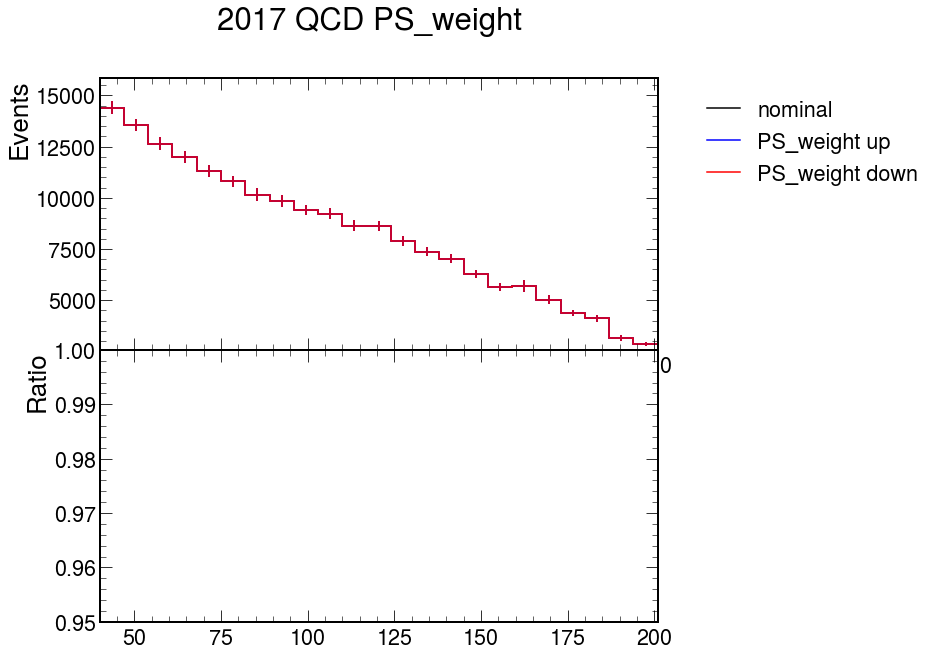

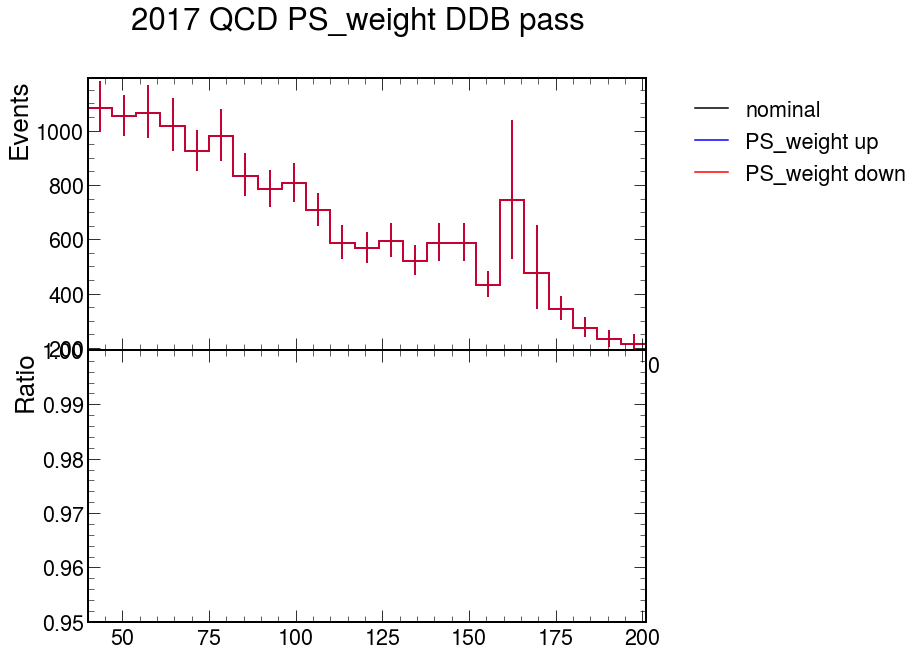

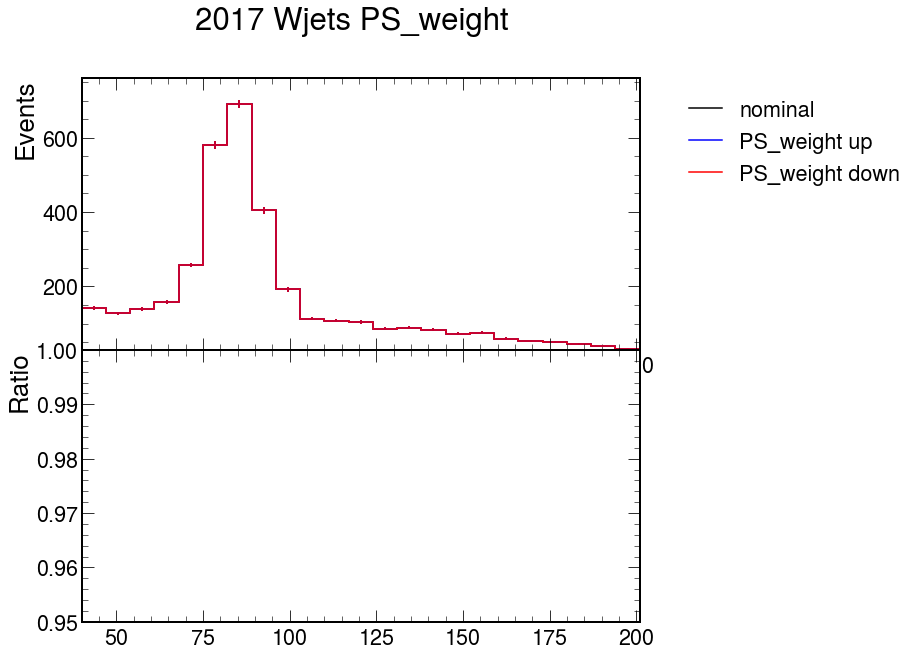

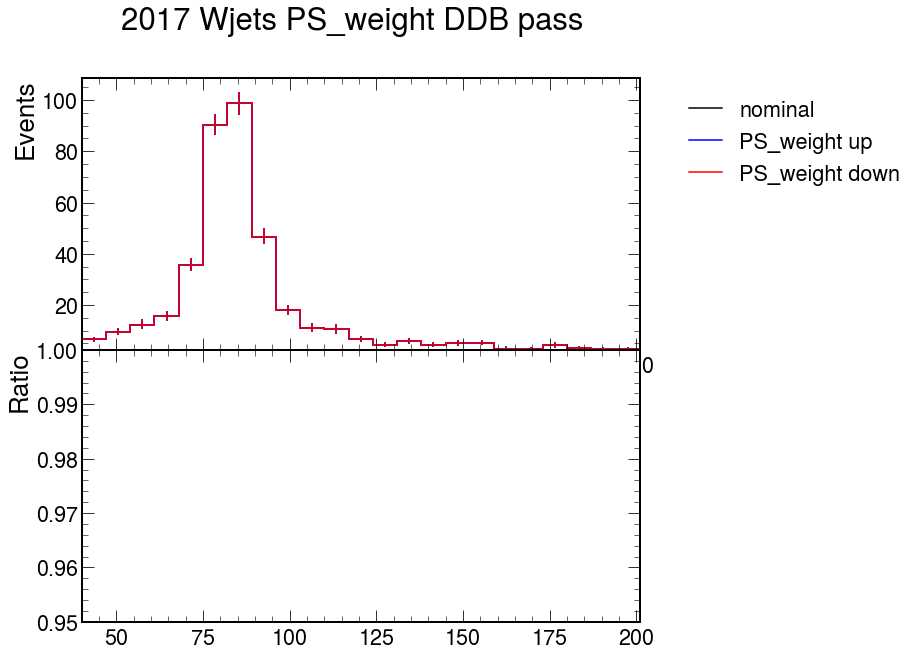

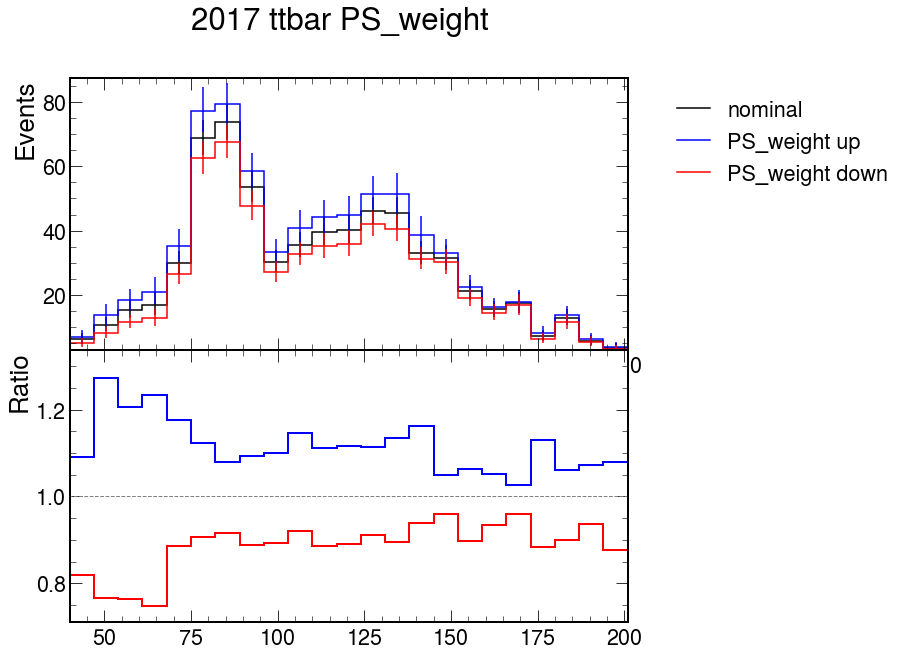

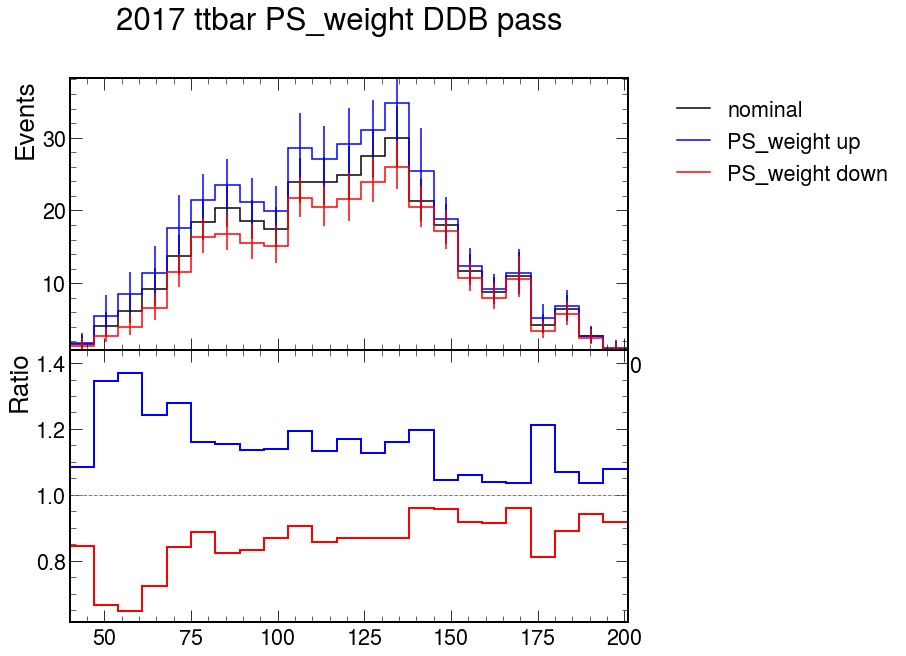

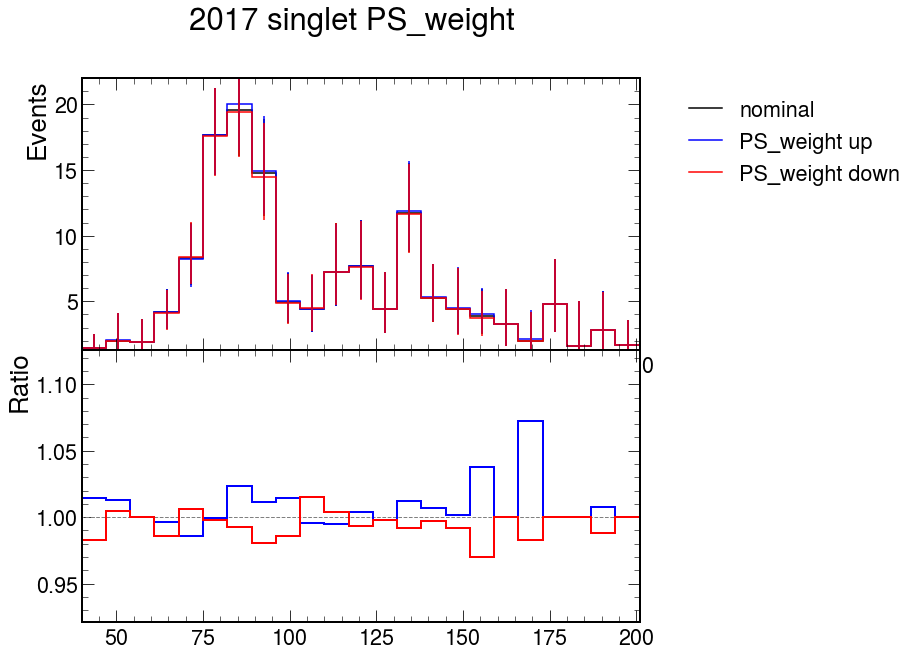

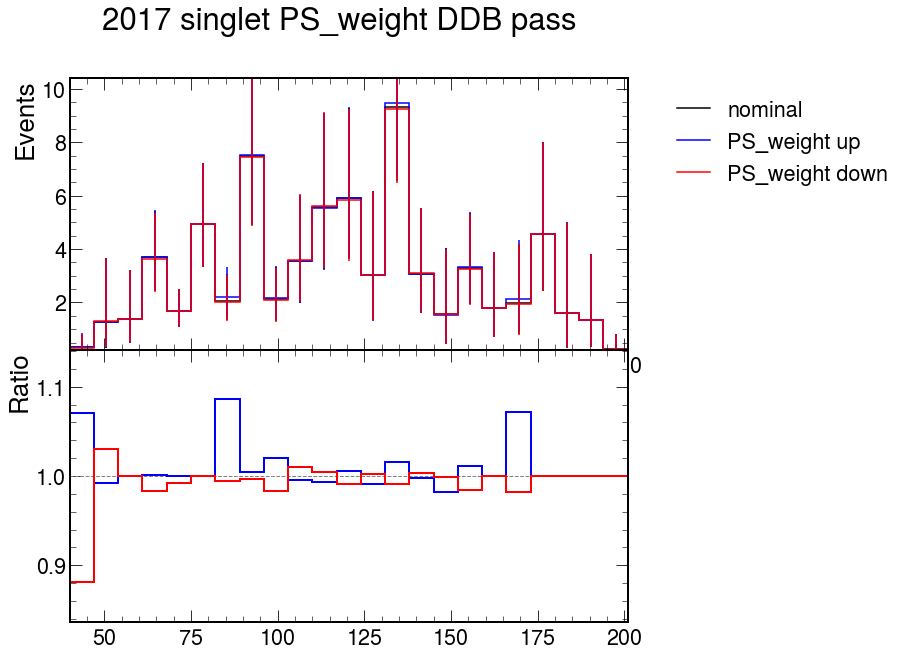

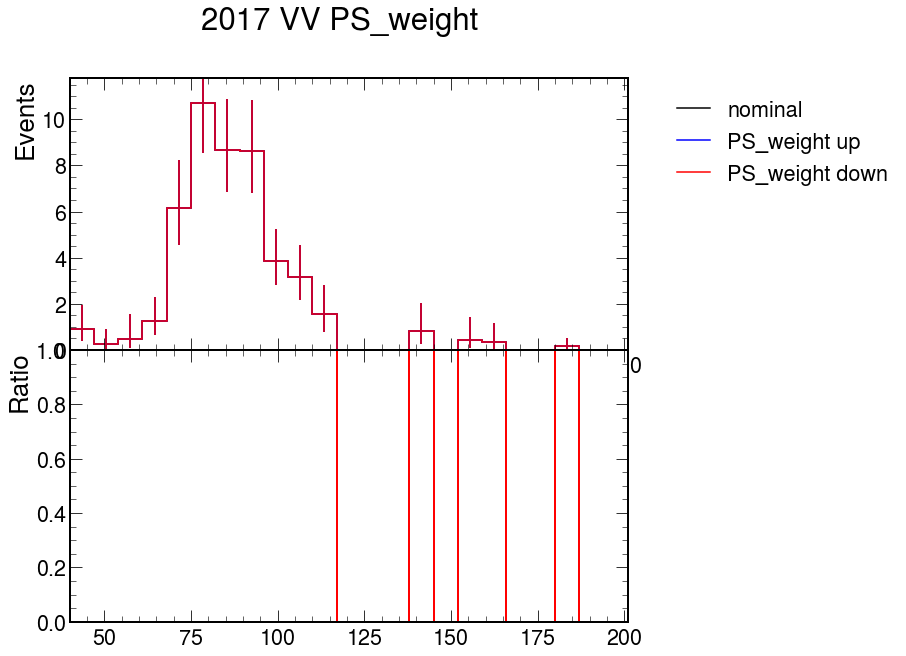

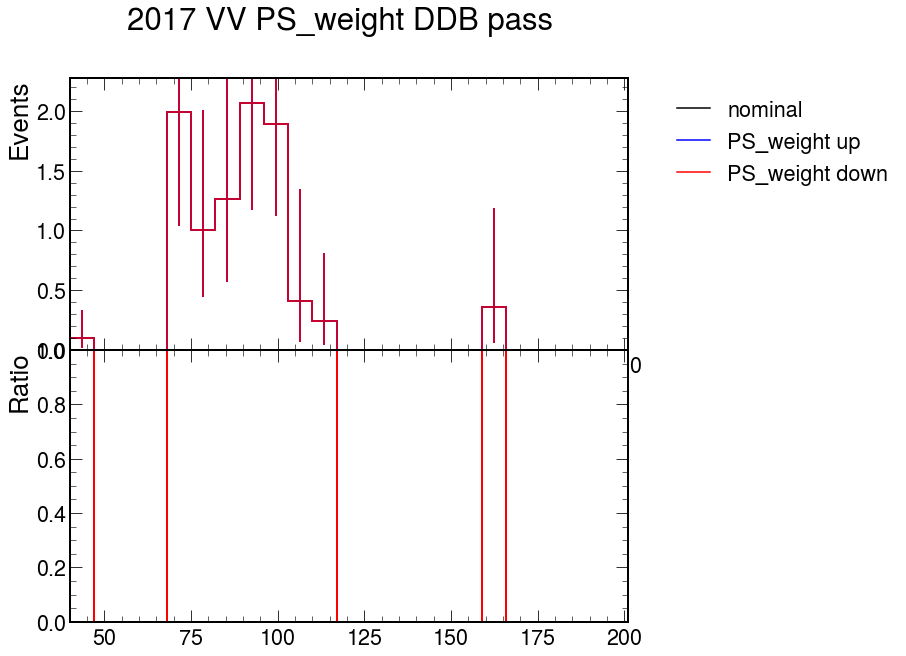

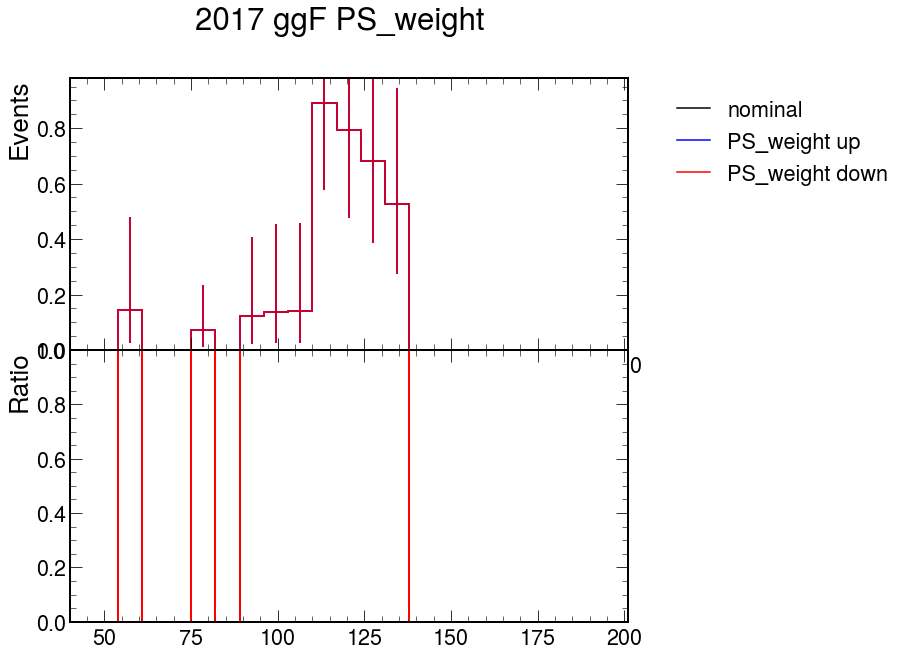

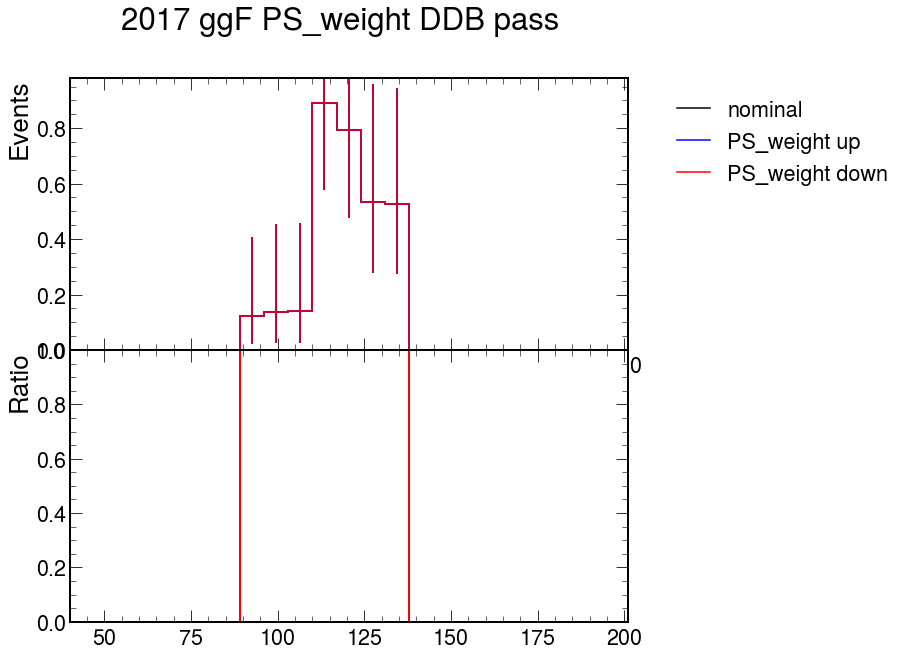

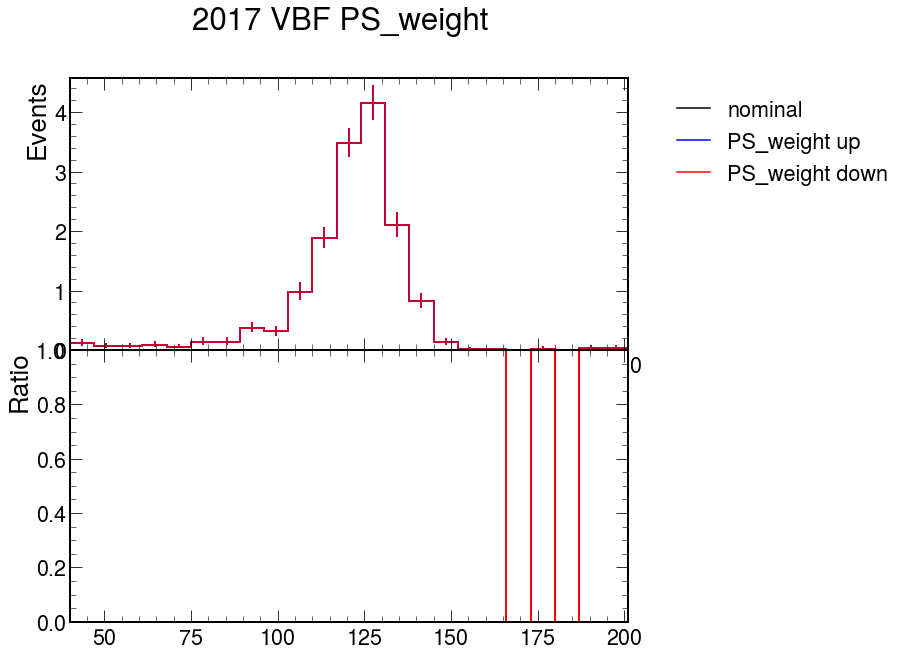

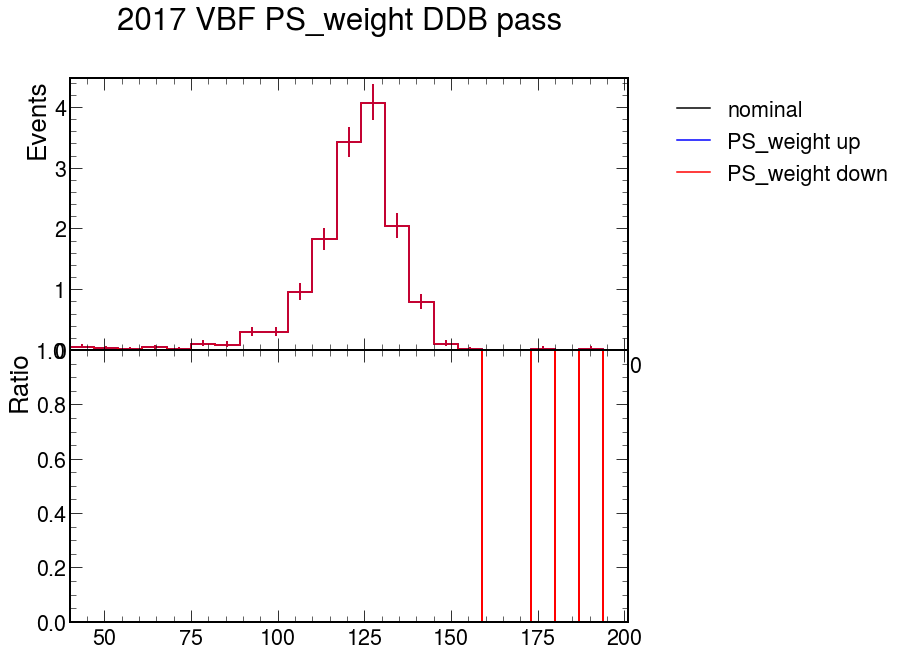

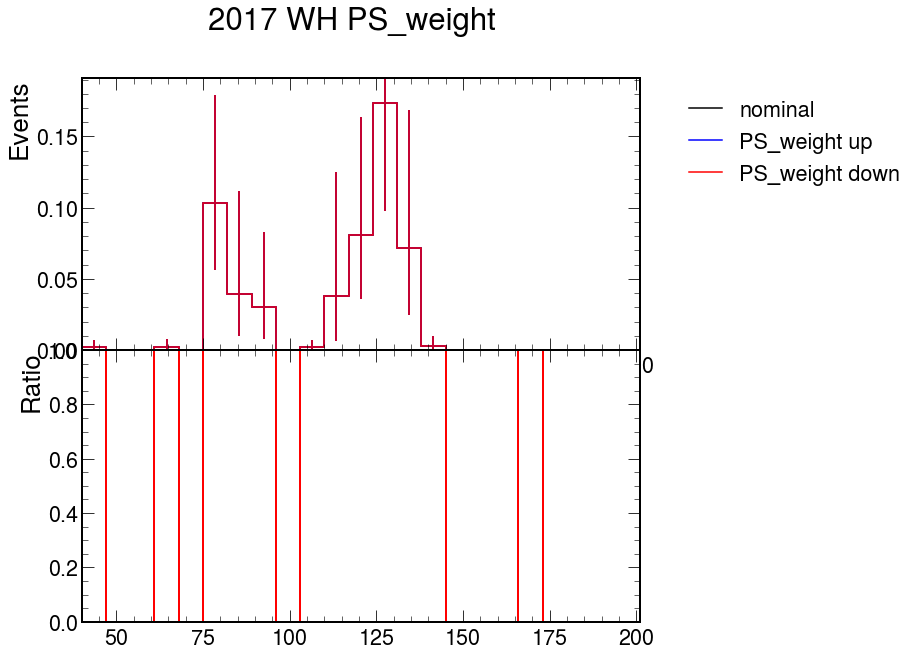

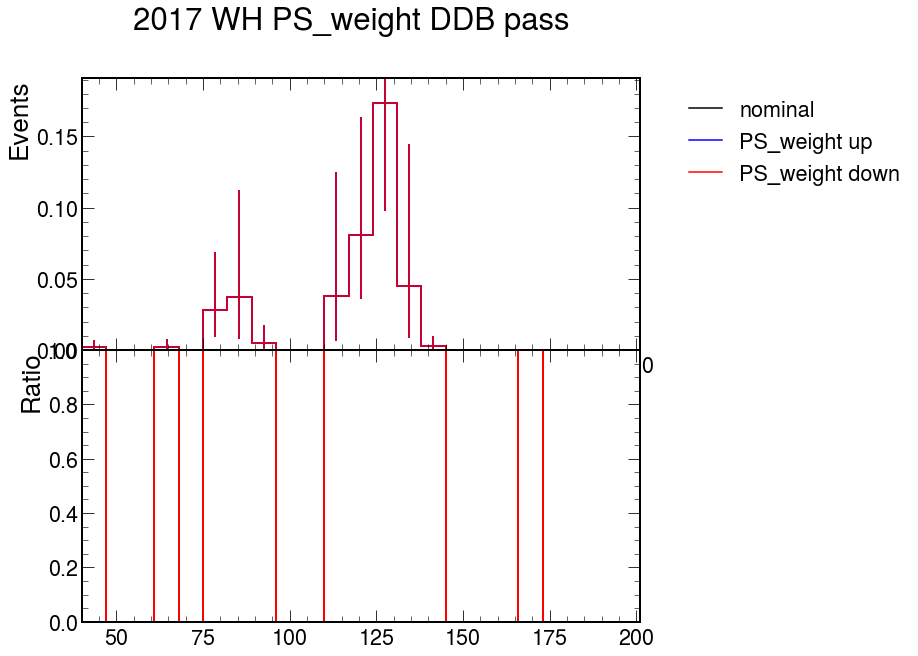

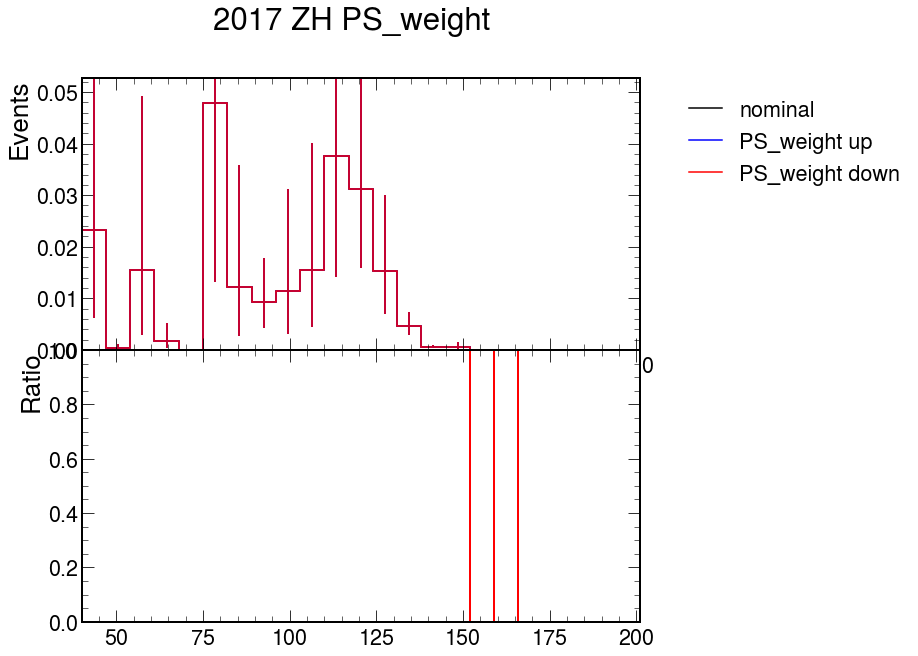

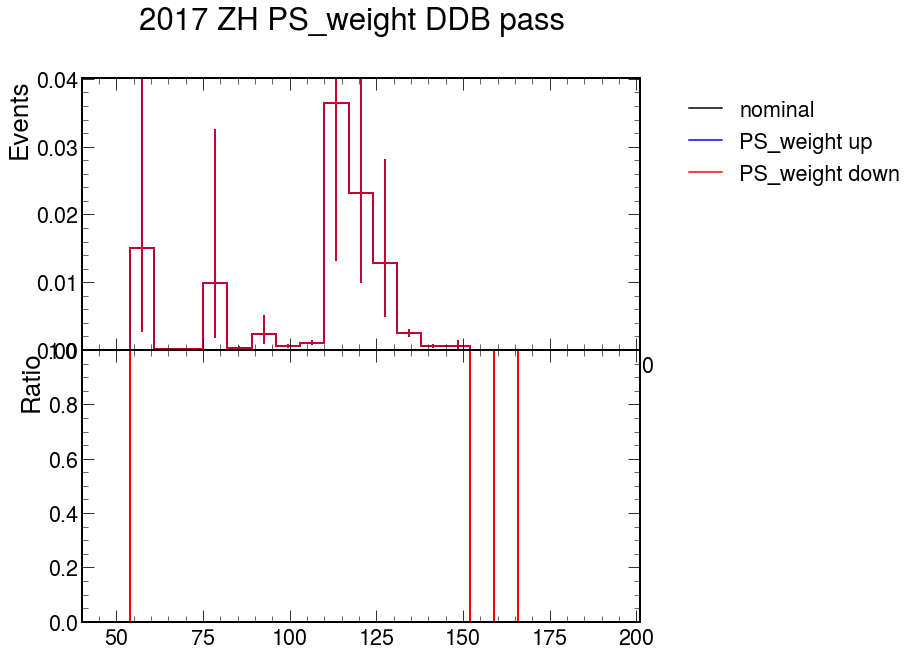

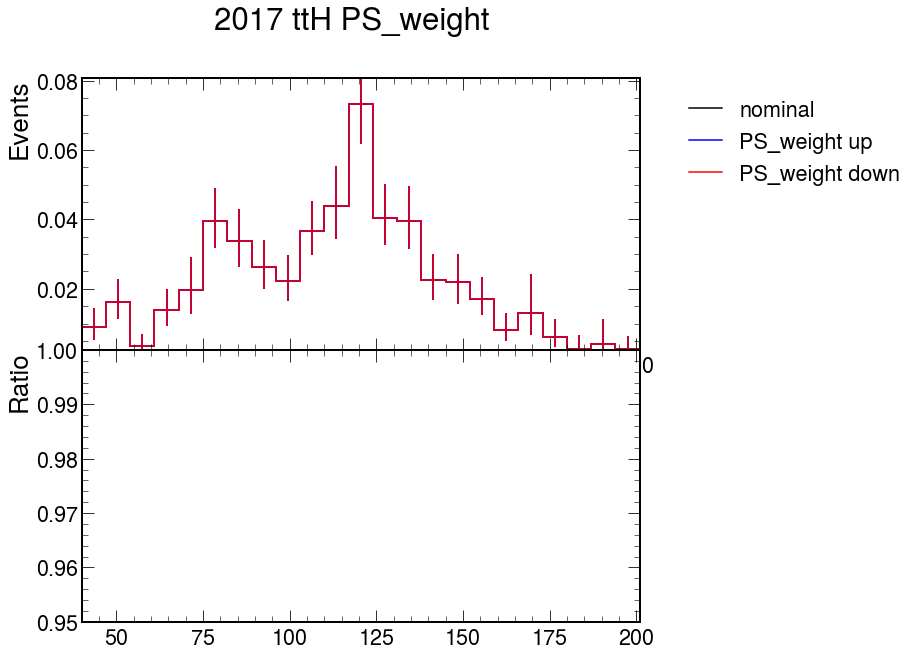

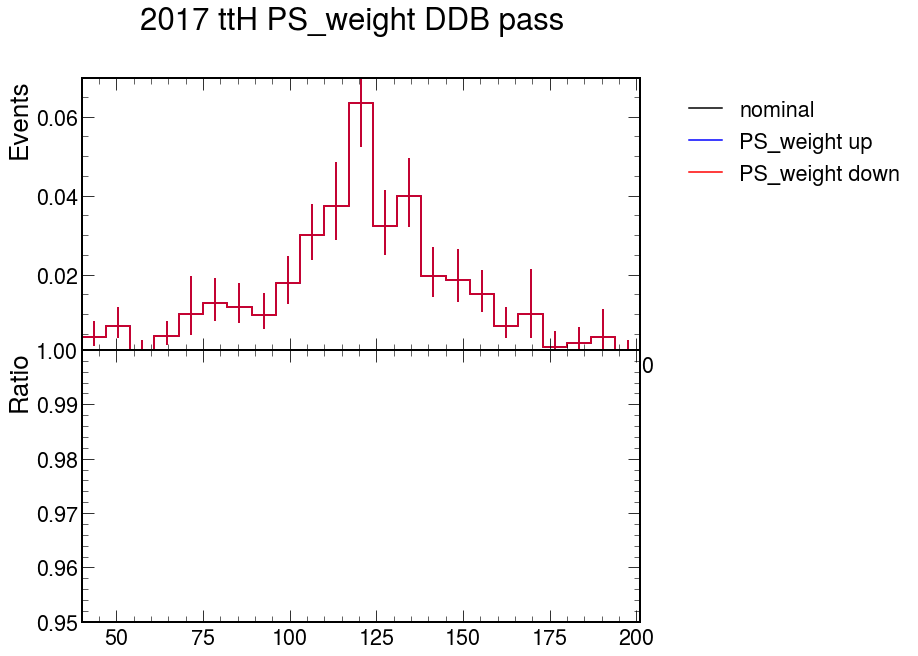

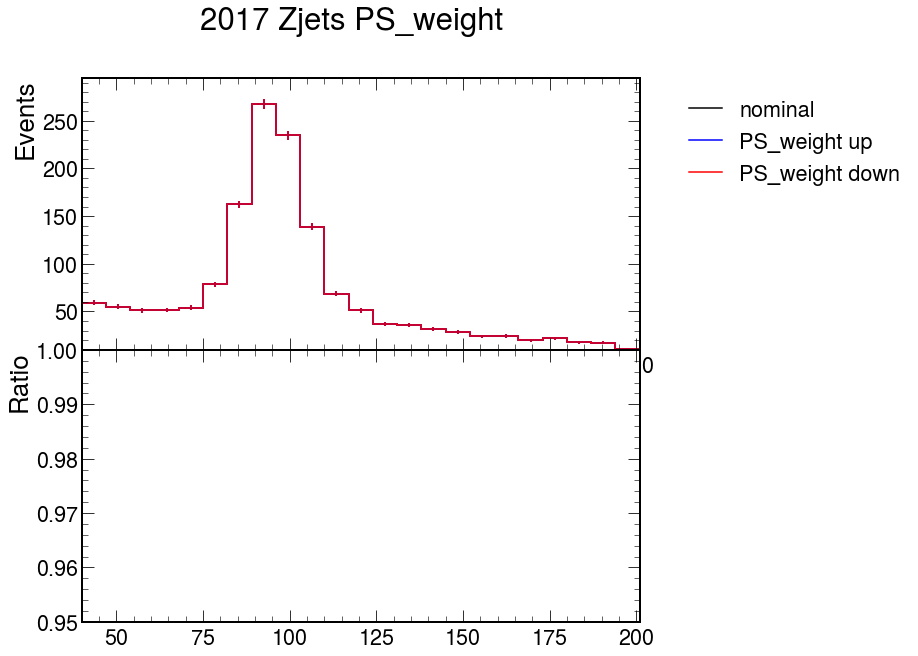

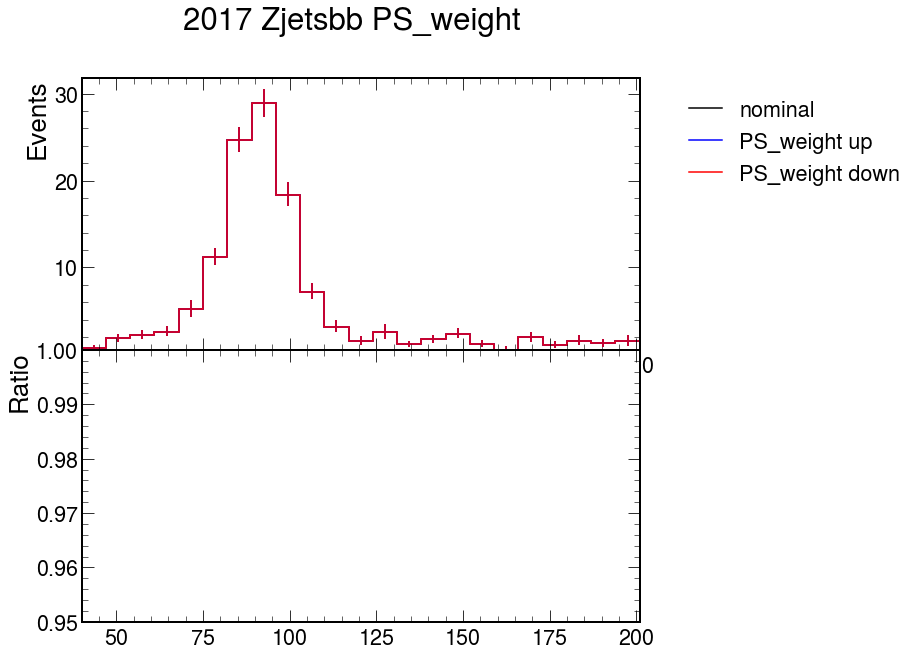

In [8]:
s = 'PS_weight'

for p in mc:
    plot_syst(h.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s,year+'/syst_'+s+'/'+p)
    plot_syst(g.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s+' DDB pass',year+'/syst_'+s+'/'+p+"_pass")
    
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(0,3)),s,year+' Zjets '+s,year+'/syst_'+s+'/Zjets')
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(3,4)),s,year+' Zjetsbb '+s,year+'/syst_'+s+'/Zjetsbb')

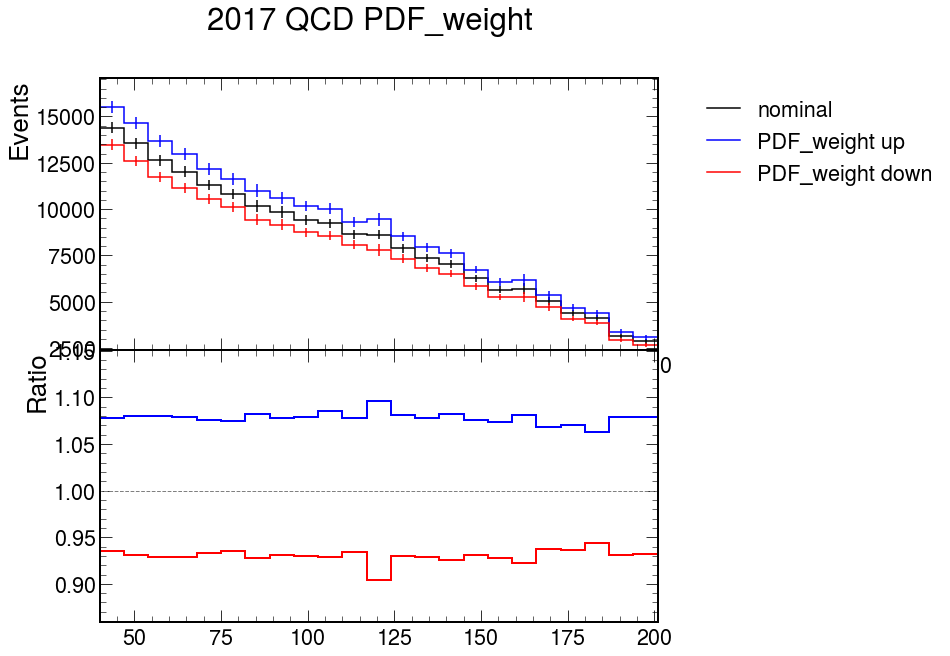

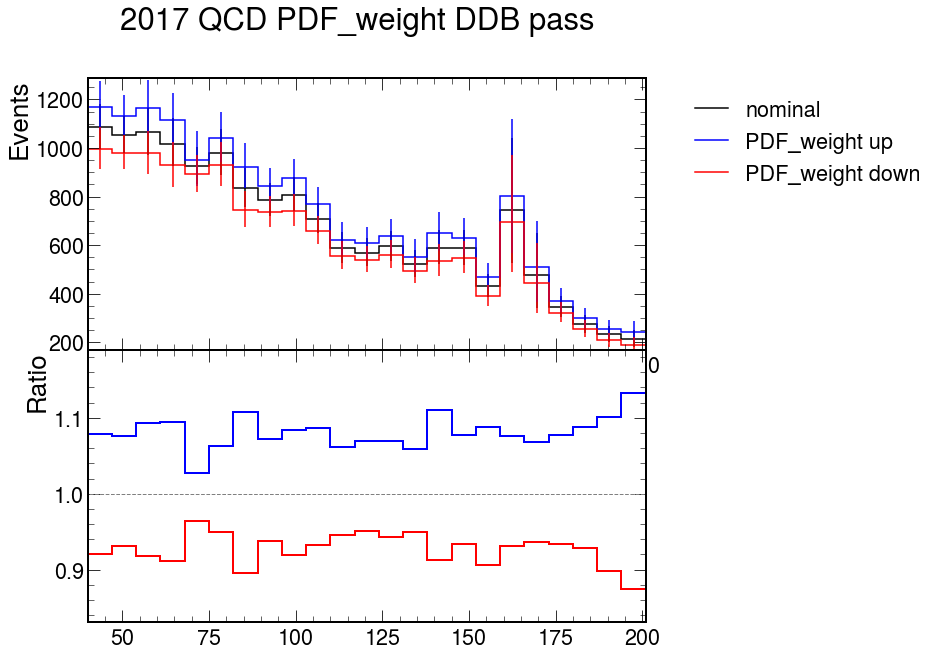

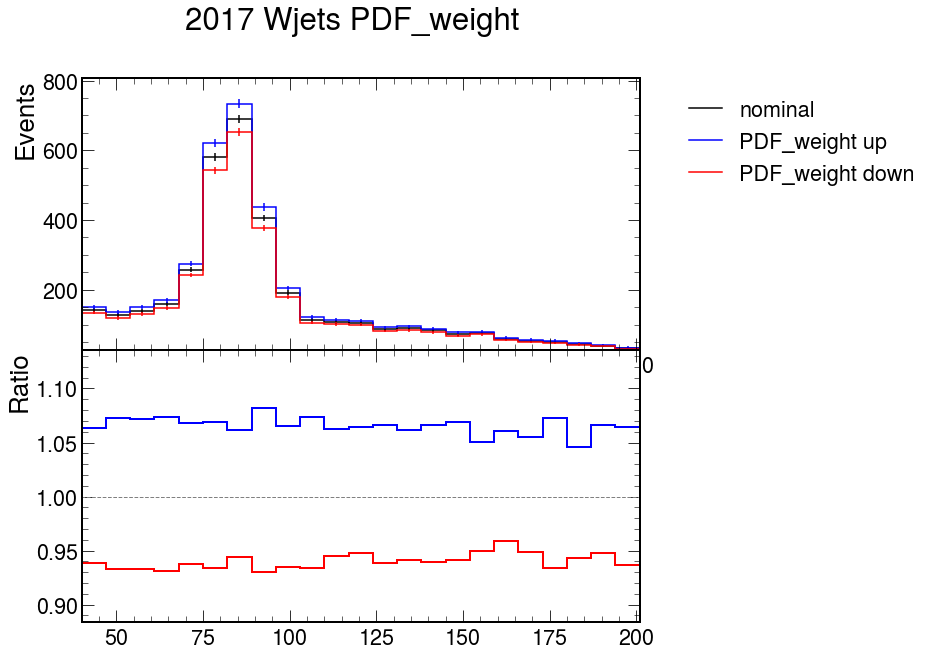

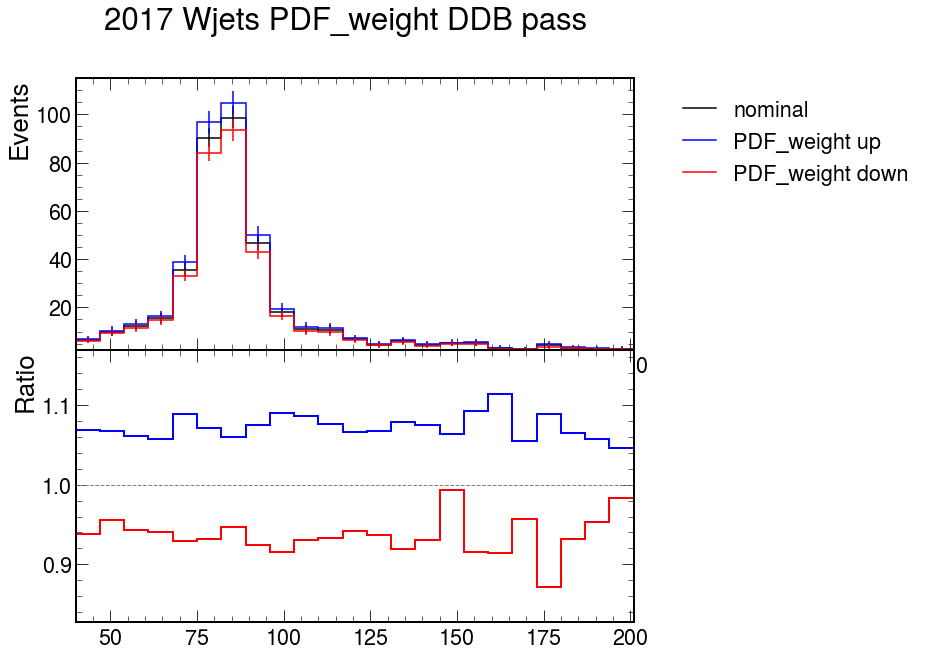

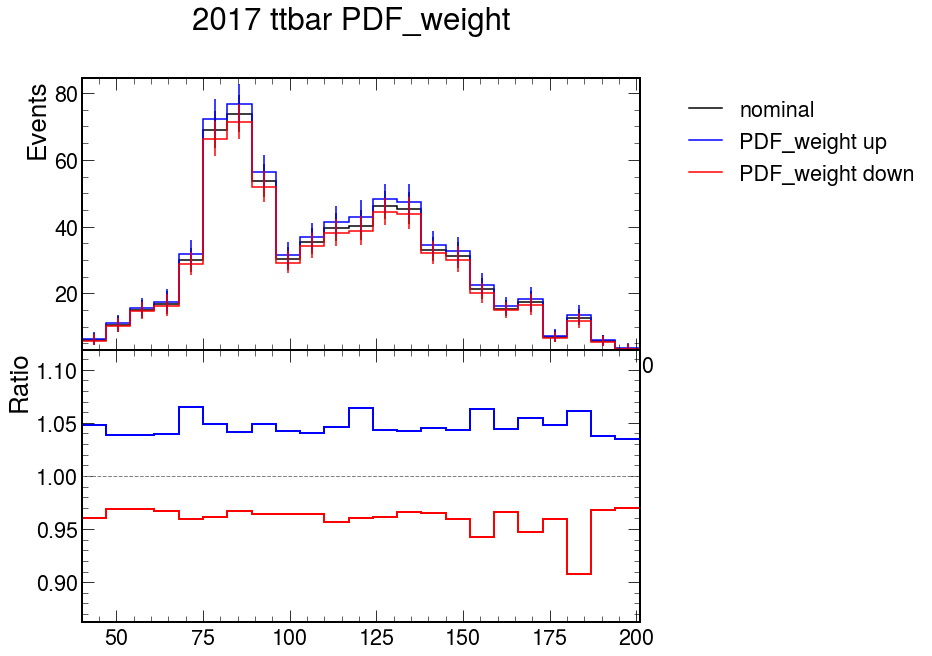

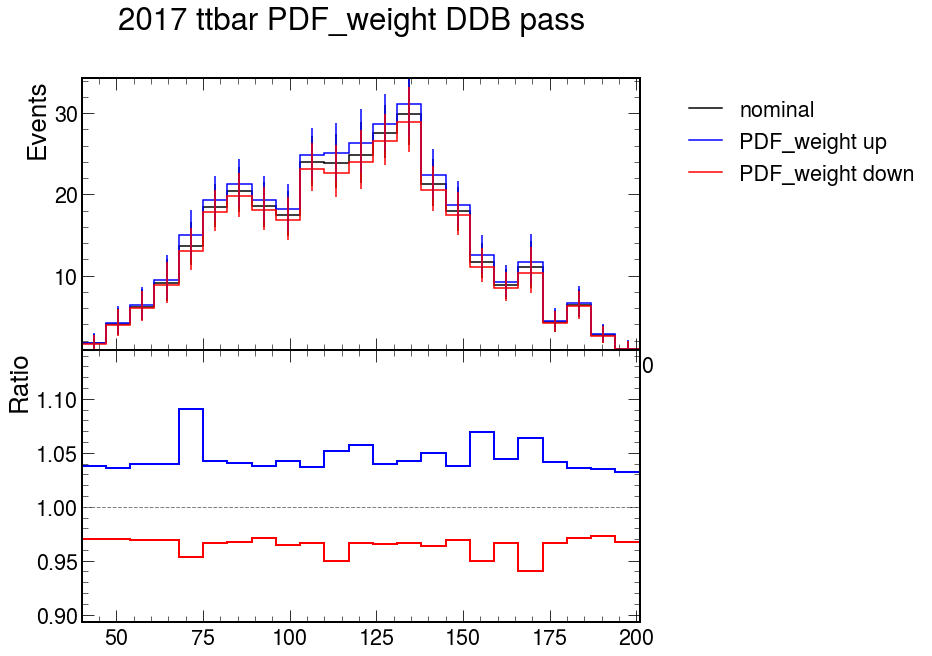

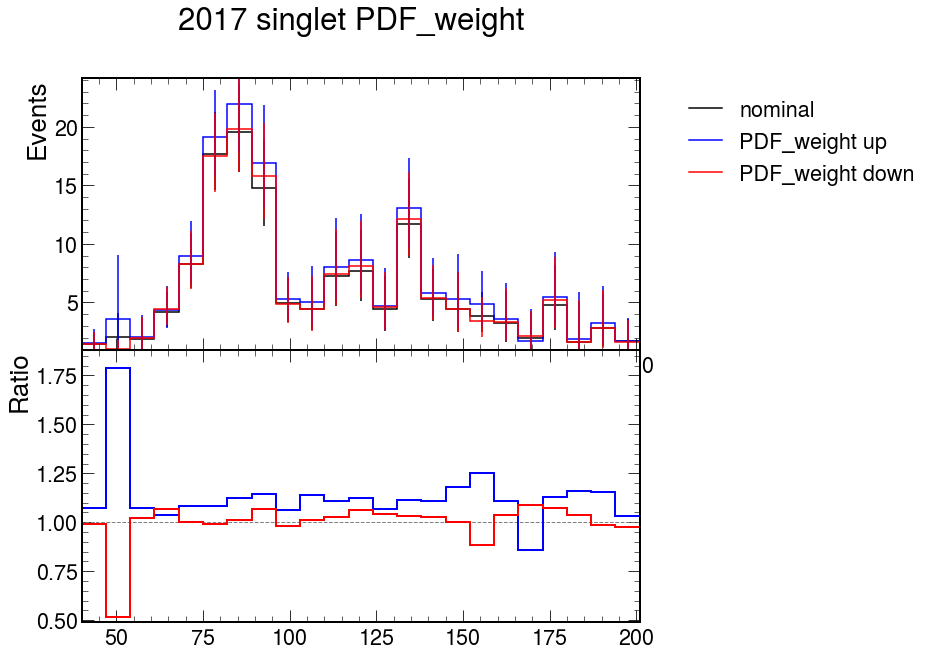

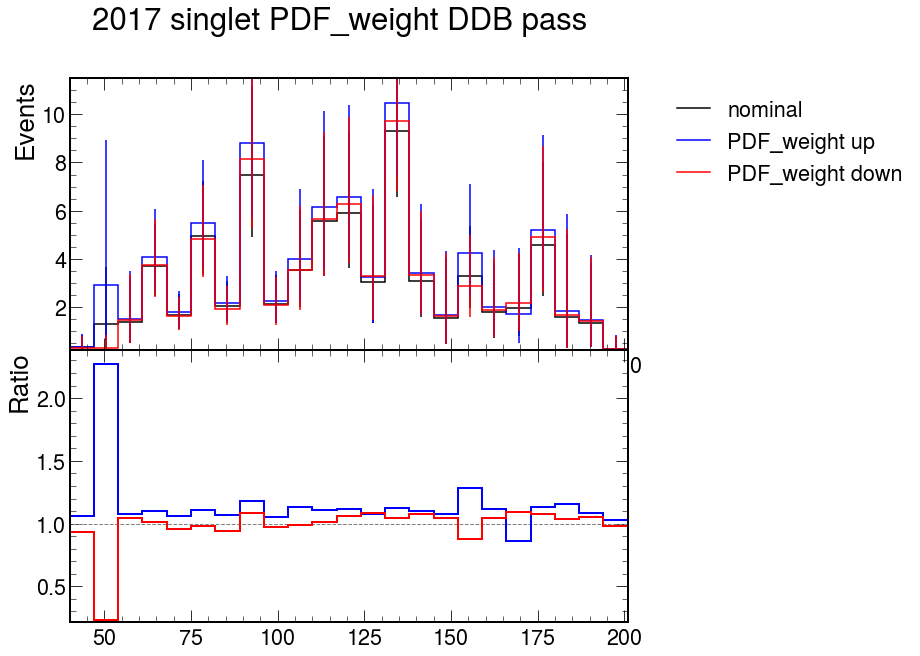

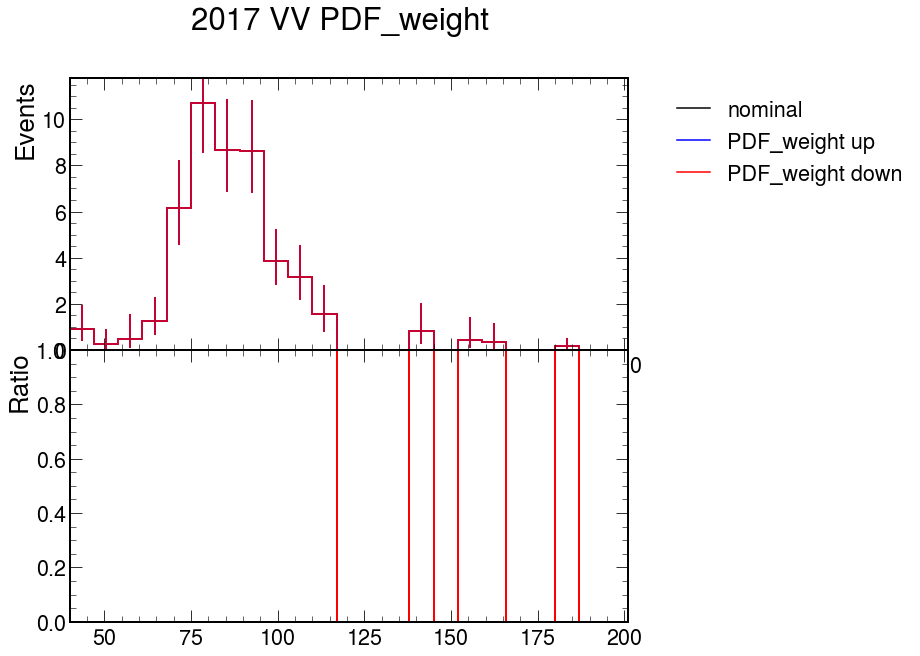

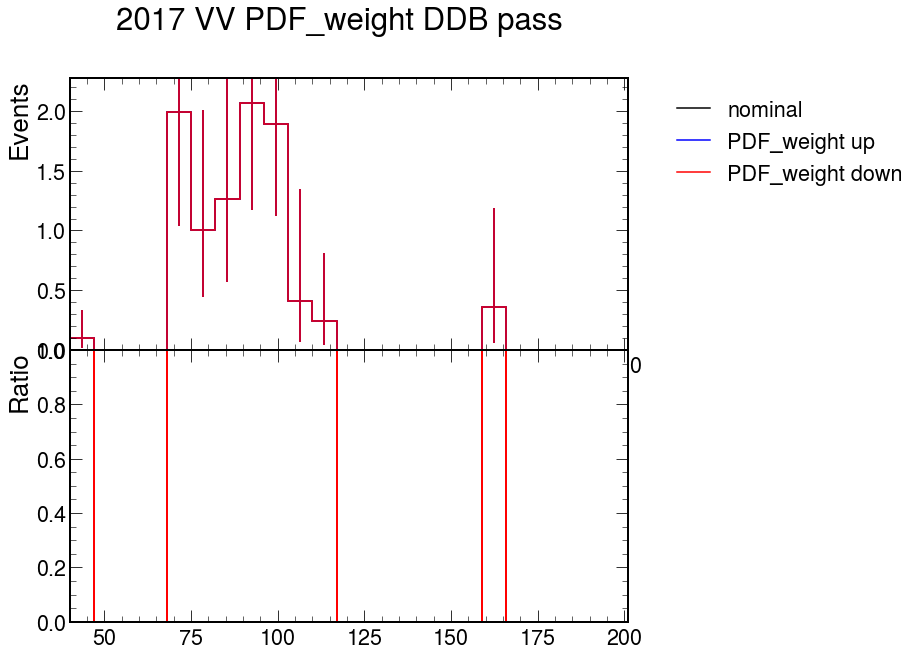

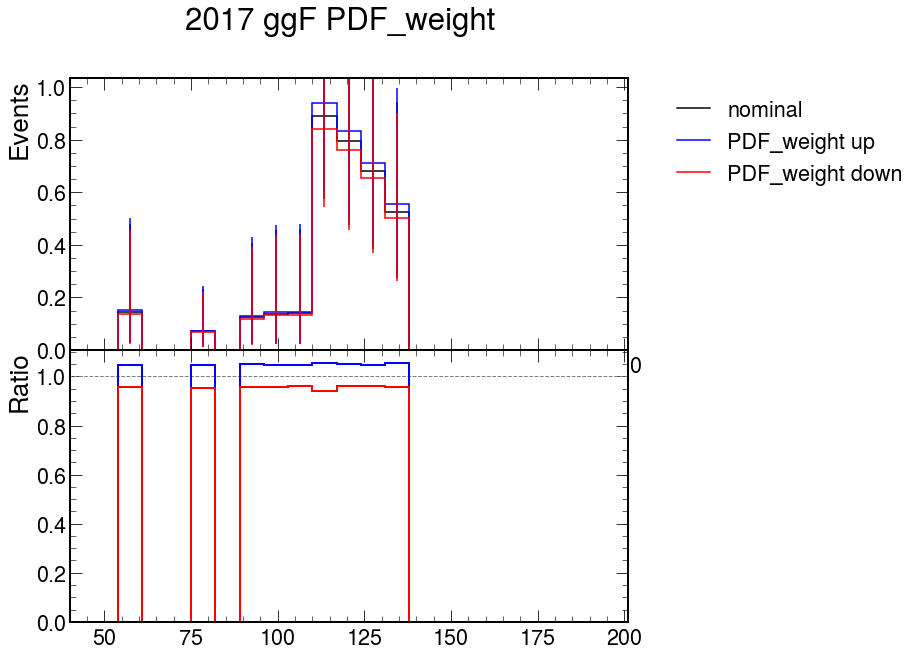

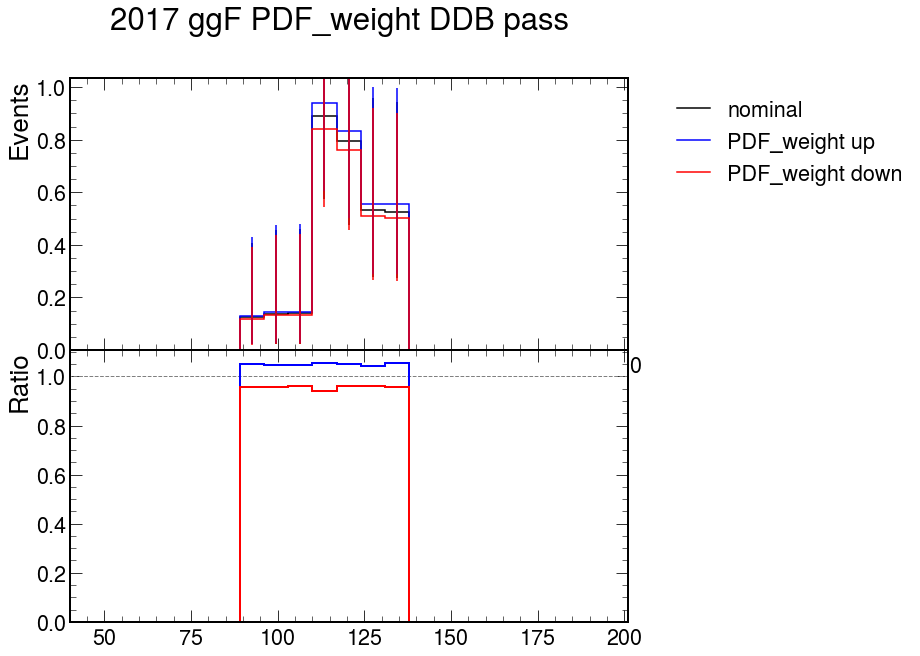

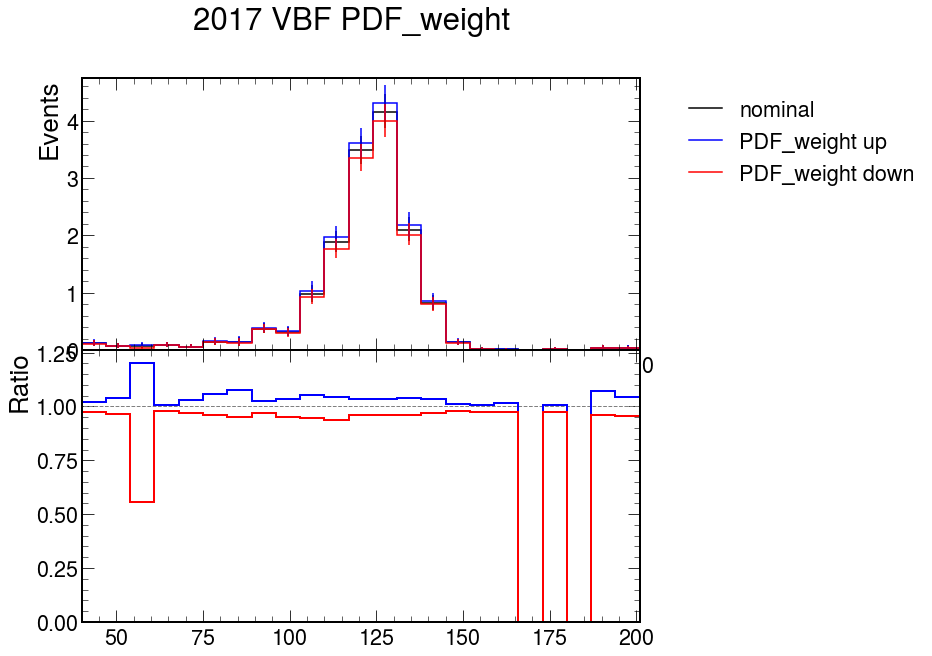

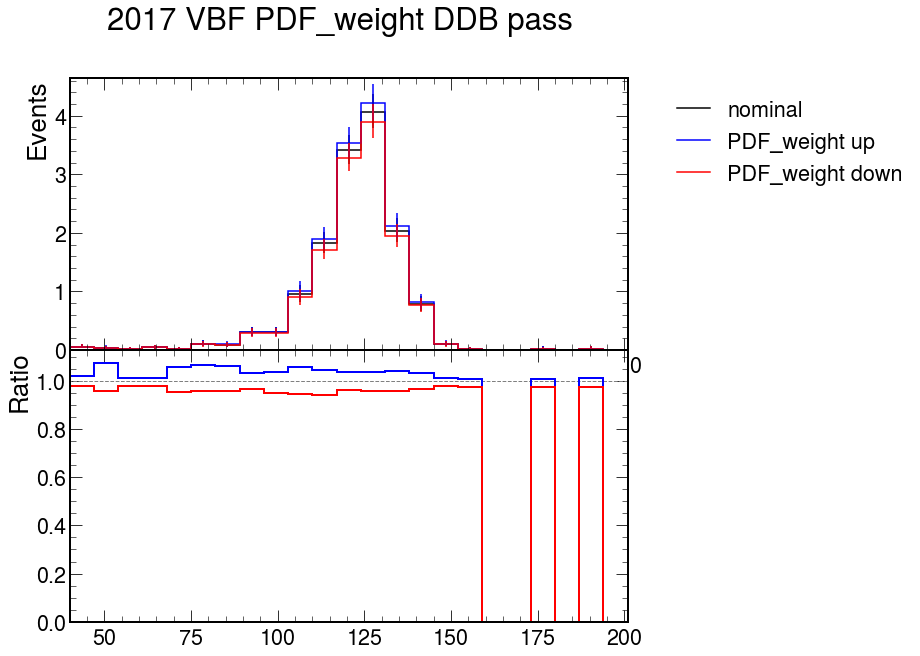

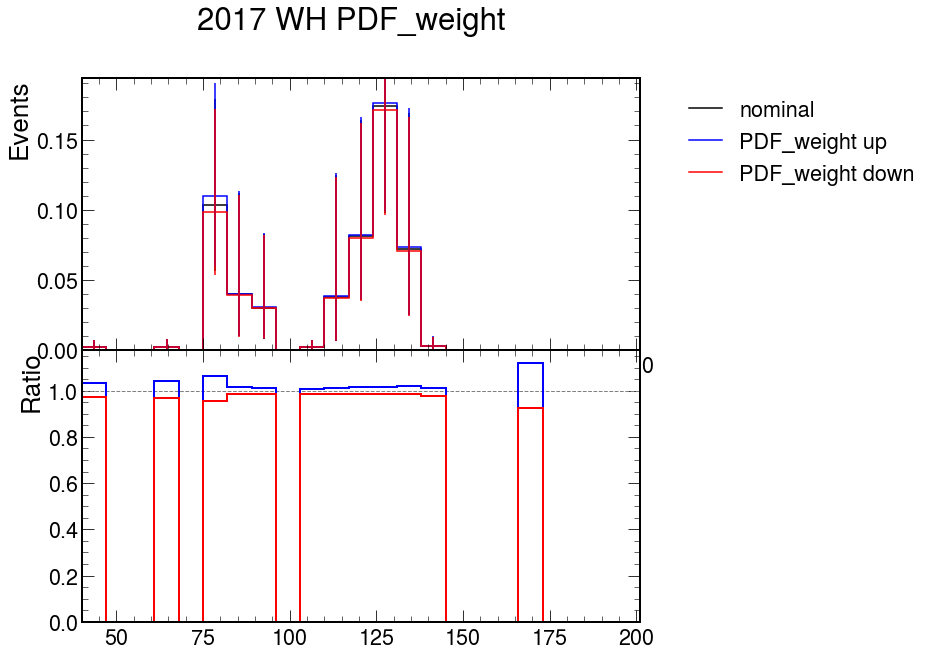

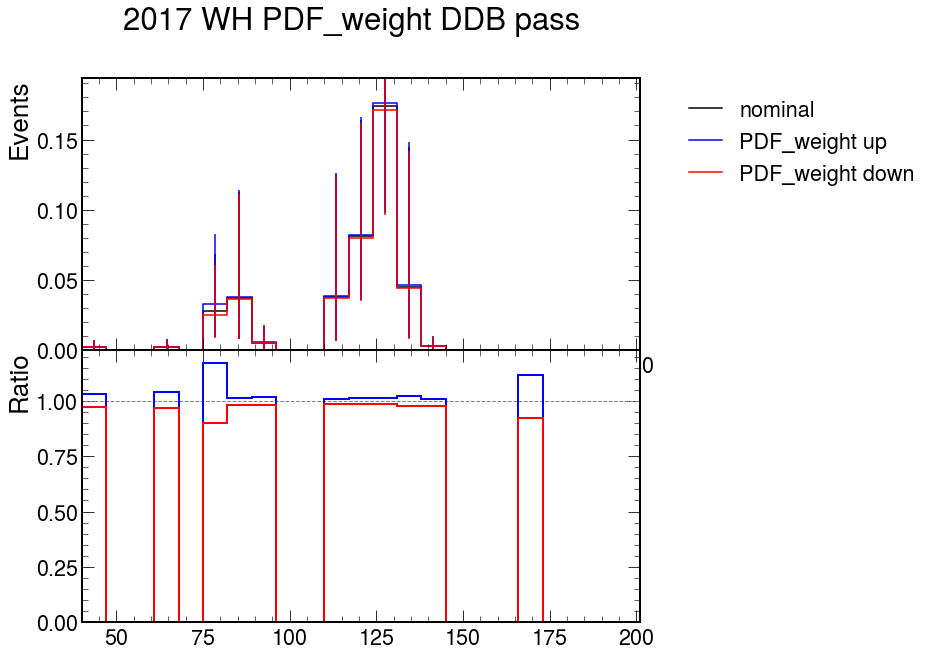

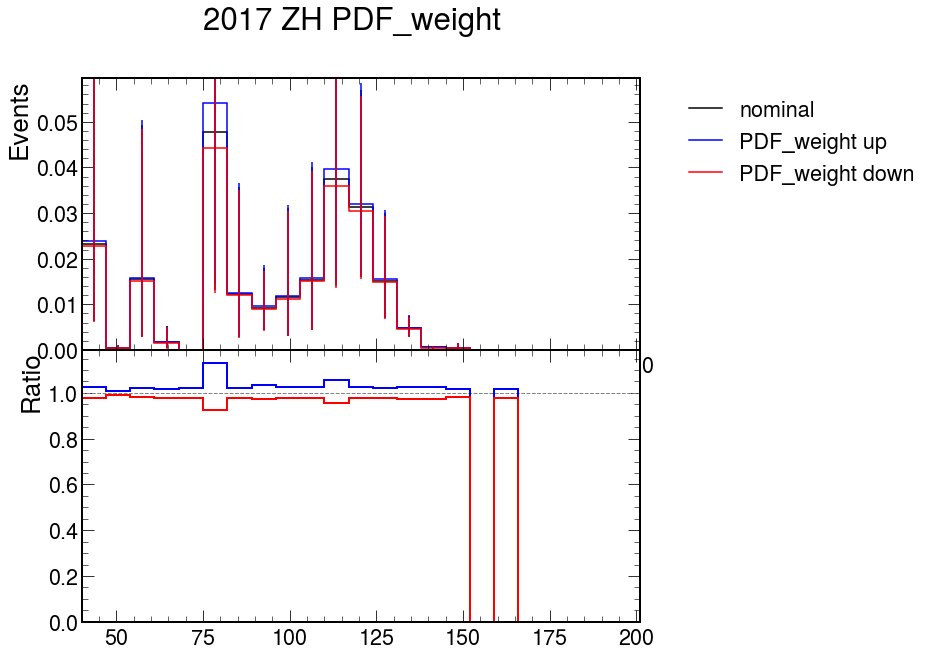

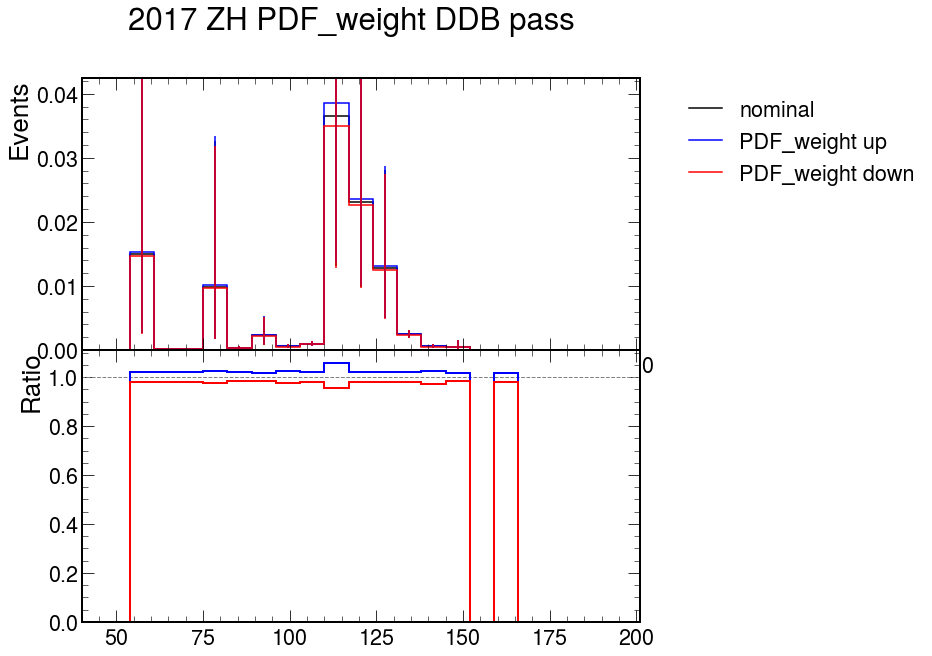

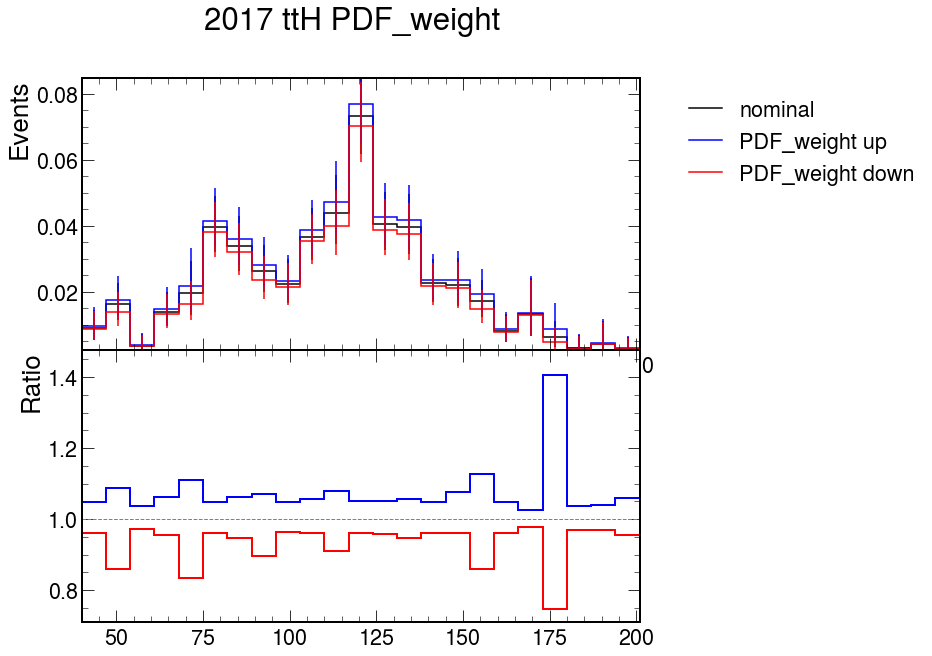

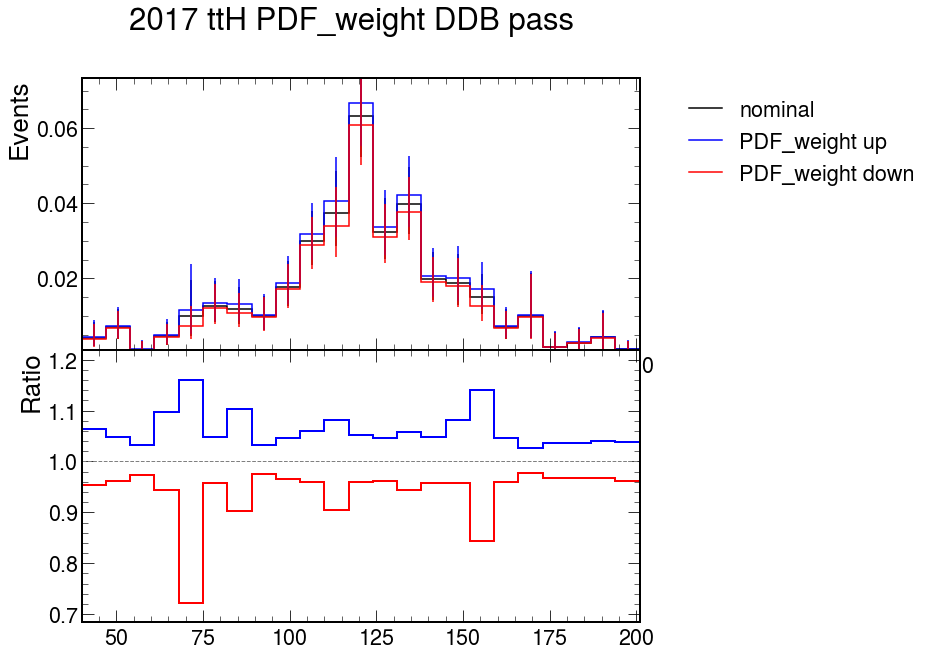

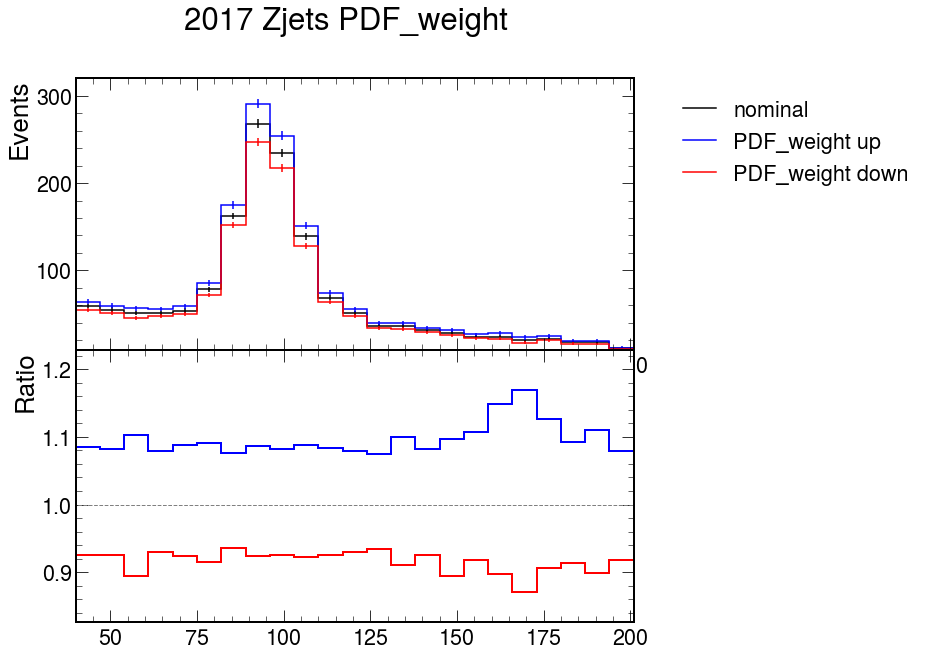

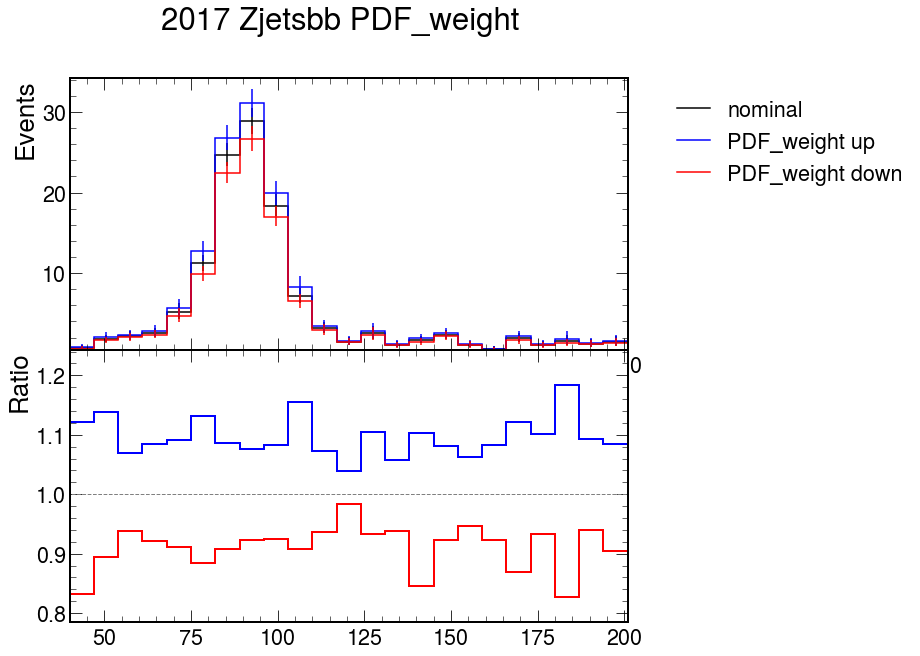

In [10]:
s = 'PDF_weight'

for p in mc:
    plot_syst(h.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s,year+'/syst_'+s+'/'+p)
    plot_syst(g.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s+' DDB pass',year+'/syst_'+s+'/'+p+"_pass")
    
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(0,3)),s,year+' Zjets '+s,year+'/syst_'+s+'/Zjets')
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(3,4)),s,year+' Zjetsbb '+s,year+'/syst_'+s+'/Zjetsbb')

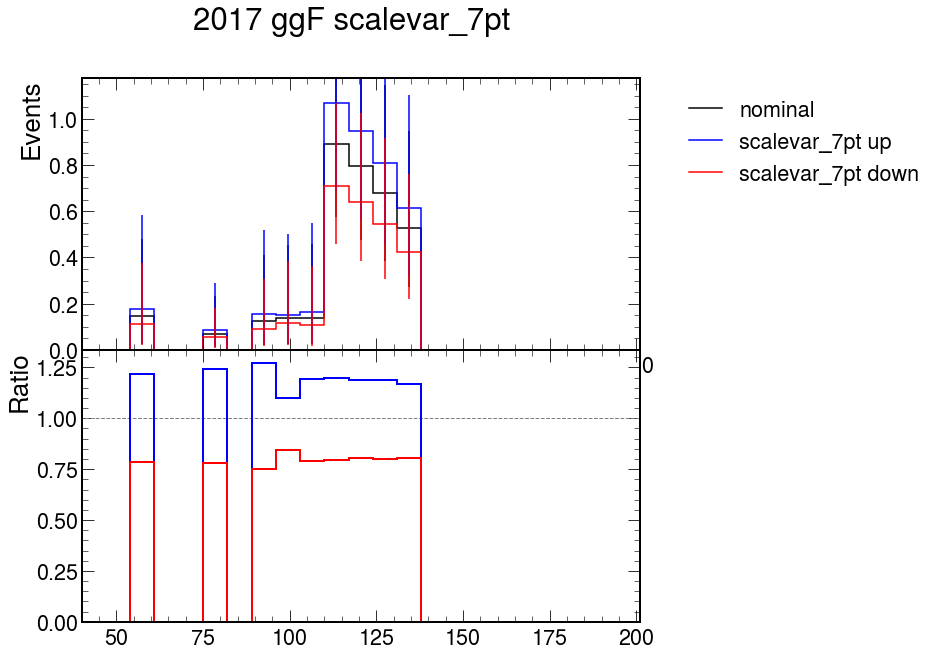

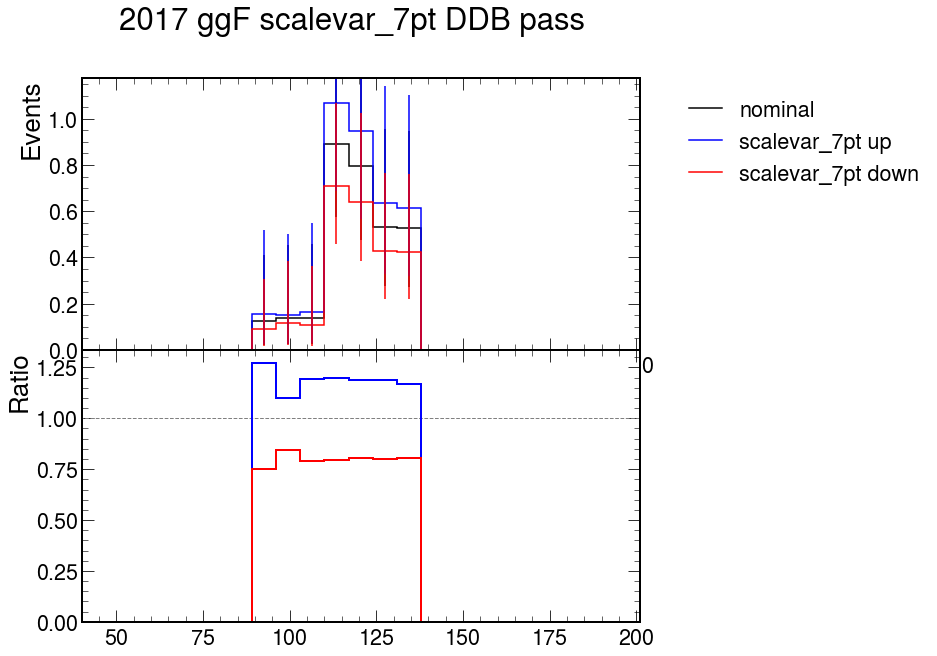

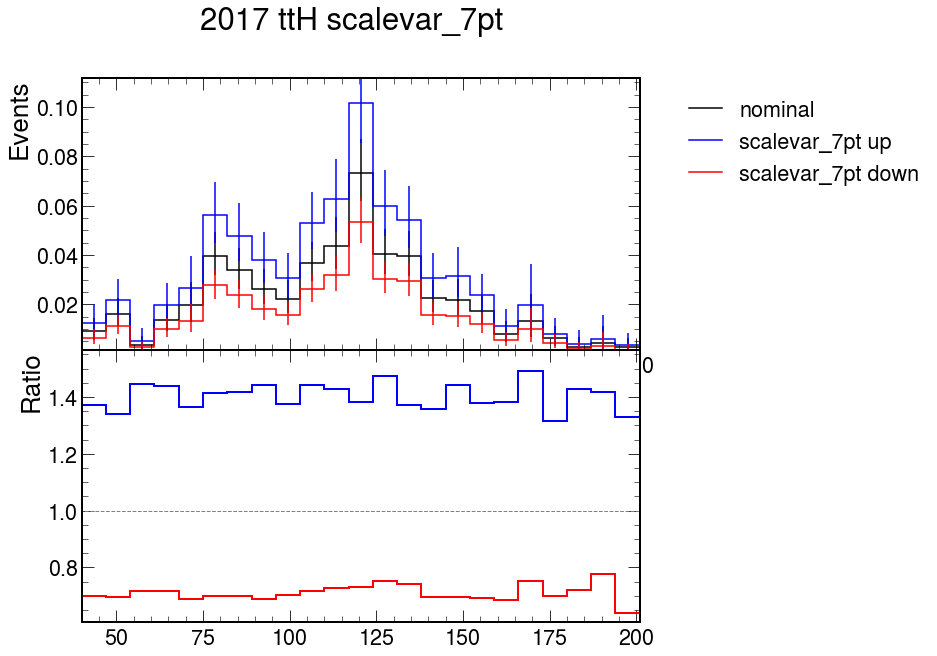

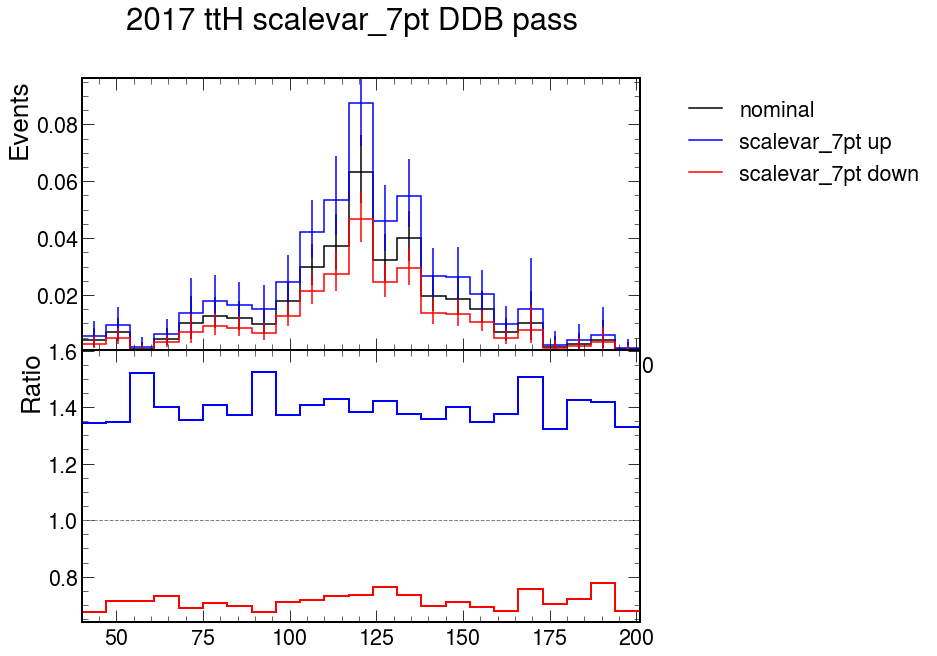

In [11]:
s = 'scalevar_7pt'

for p in ['ggF','ttH']:
    plot_syst(h.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s,year+'/syst_'+s+'/'+p)
    plot_syst(g.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s+' DDB pass',year+'/syst_'+s+'/'+p+"_pass")

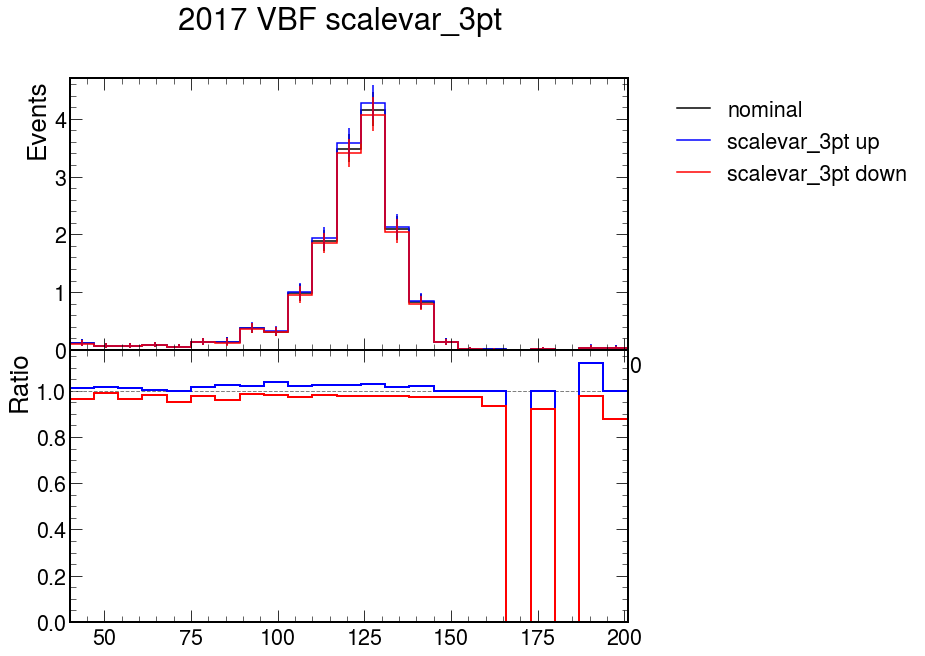

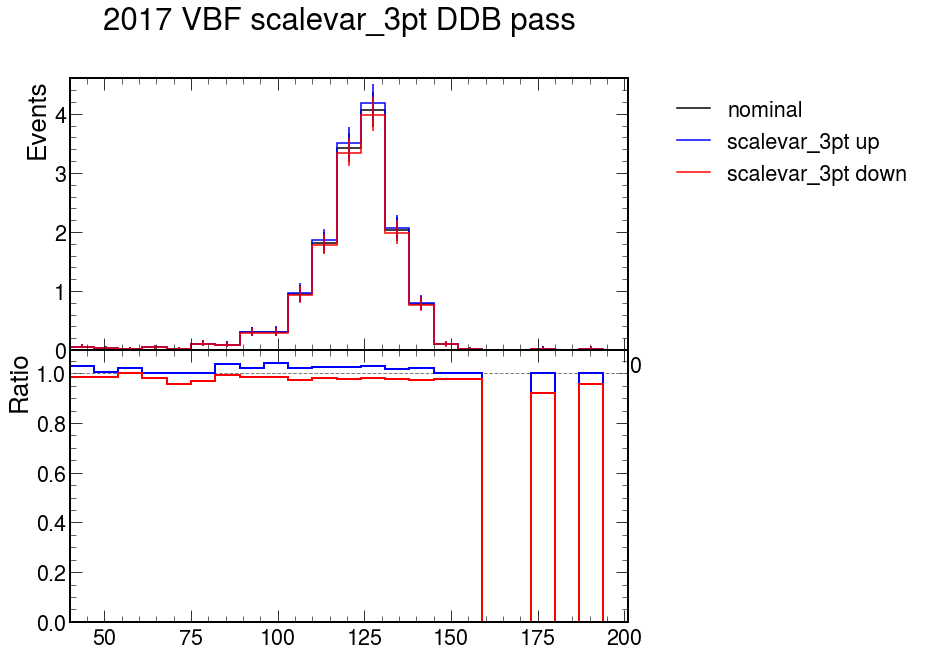

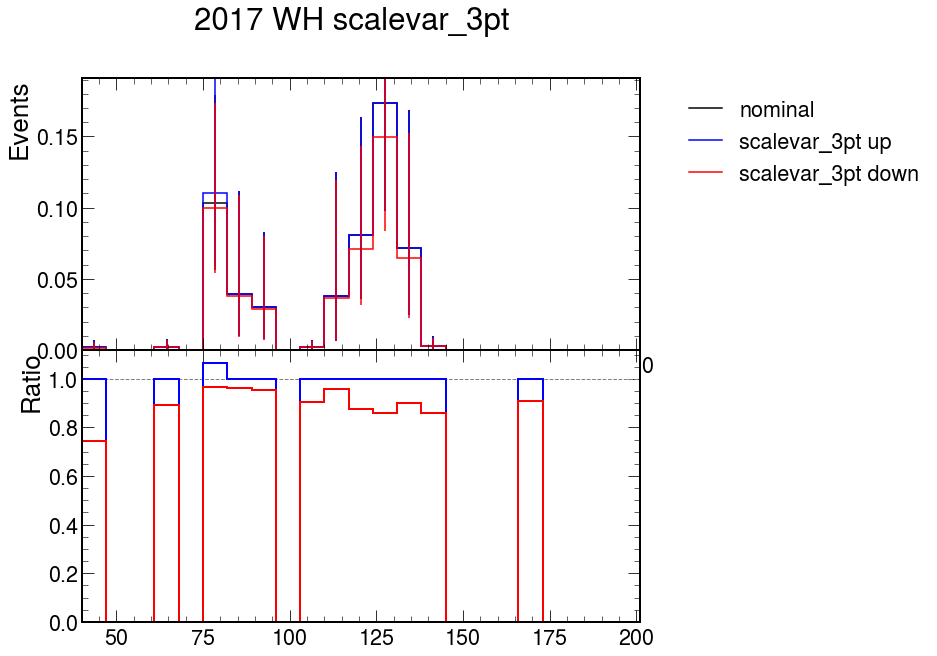

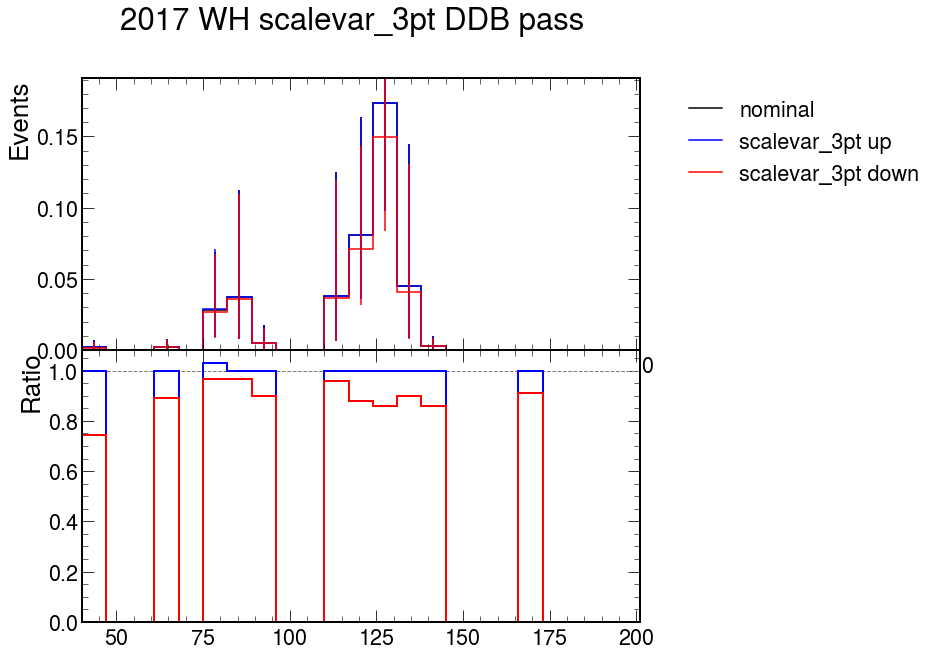

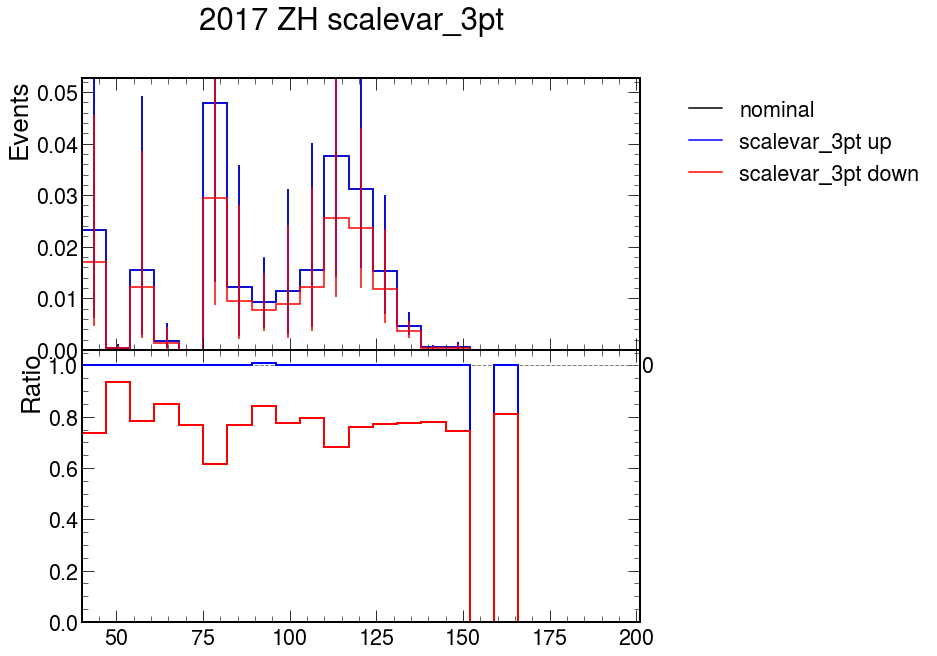

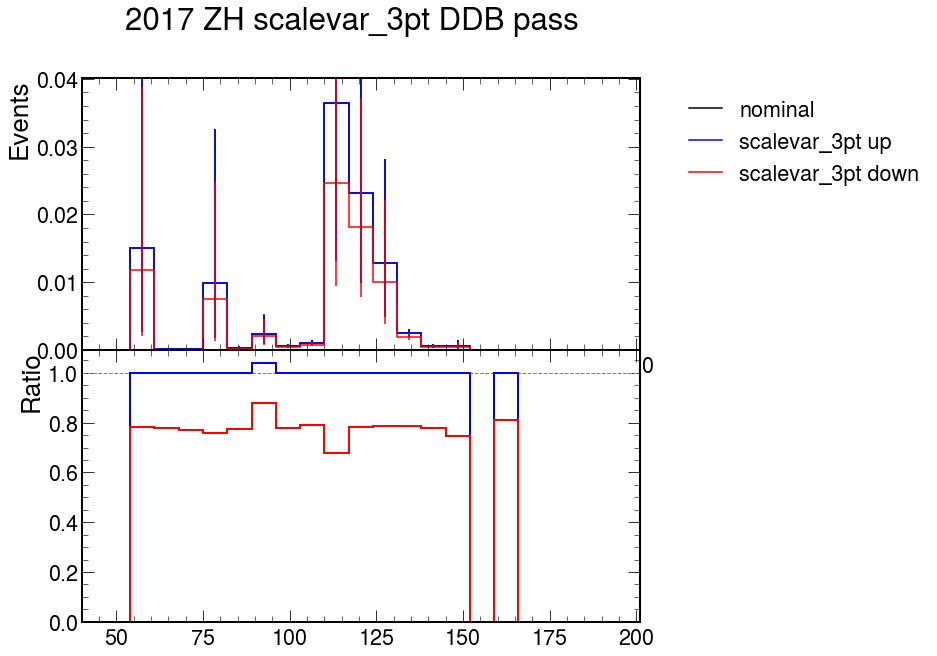

In [13]:
s = 'scalevar_3pt'

for p in ['VBF','WH','ZH']:
    plot_syst(h.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s,year+'/syst_'+s+'/'+p)
    plot_syst(g.integrate('process',p).sum('genflavor'),s,year+' '+p+' '+s+' DDB pass',year+'/syst_'+s+'/'+p+"_pass")

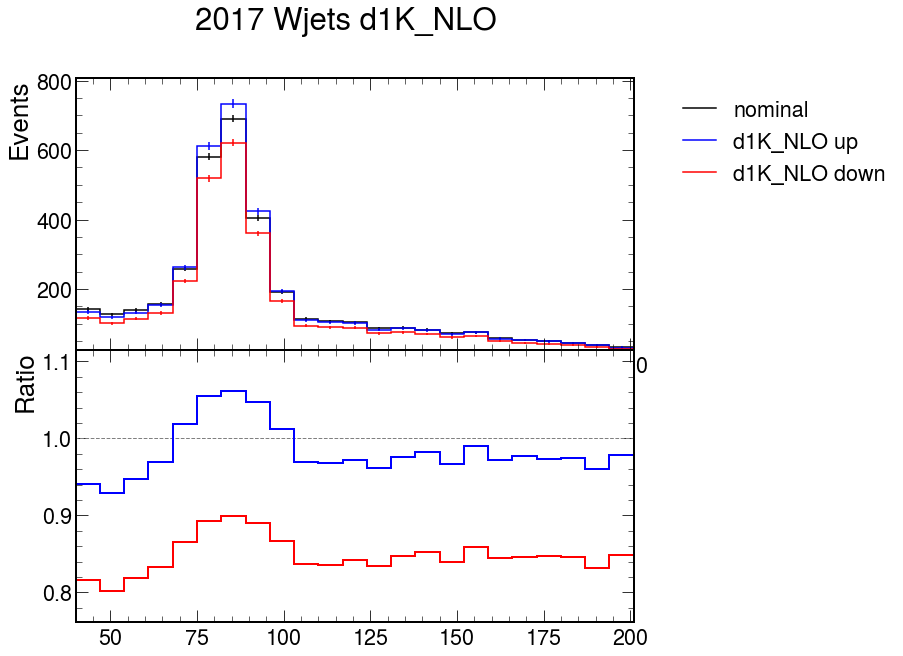

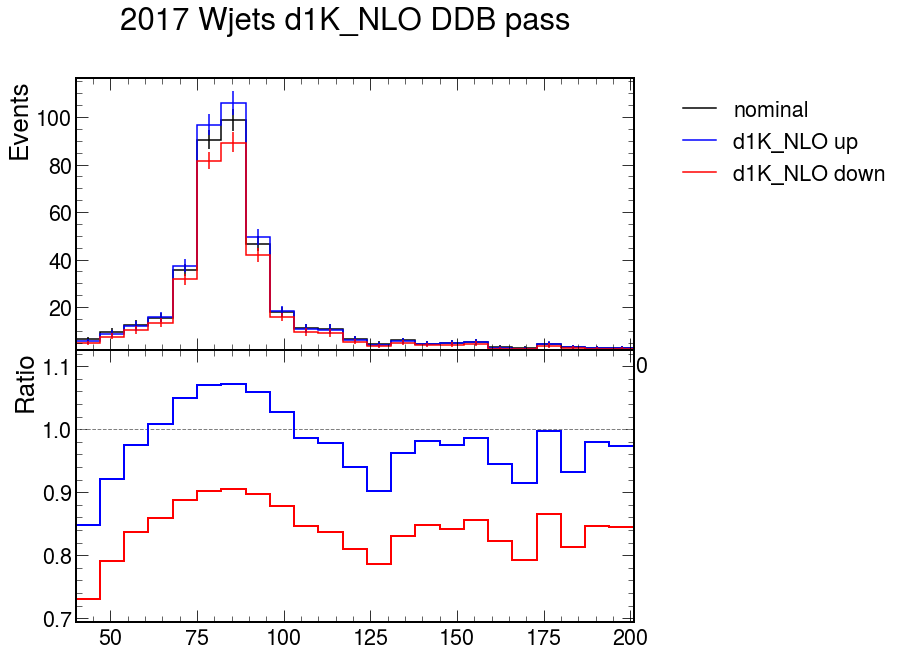

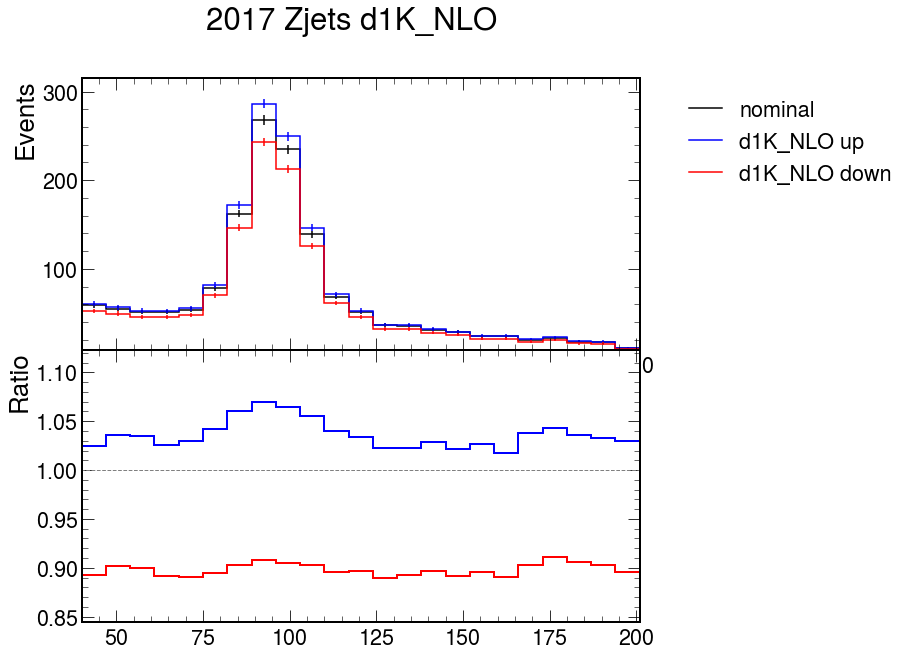

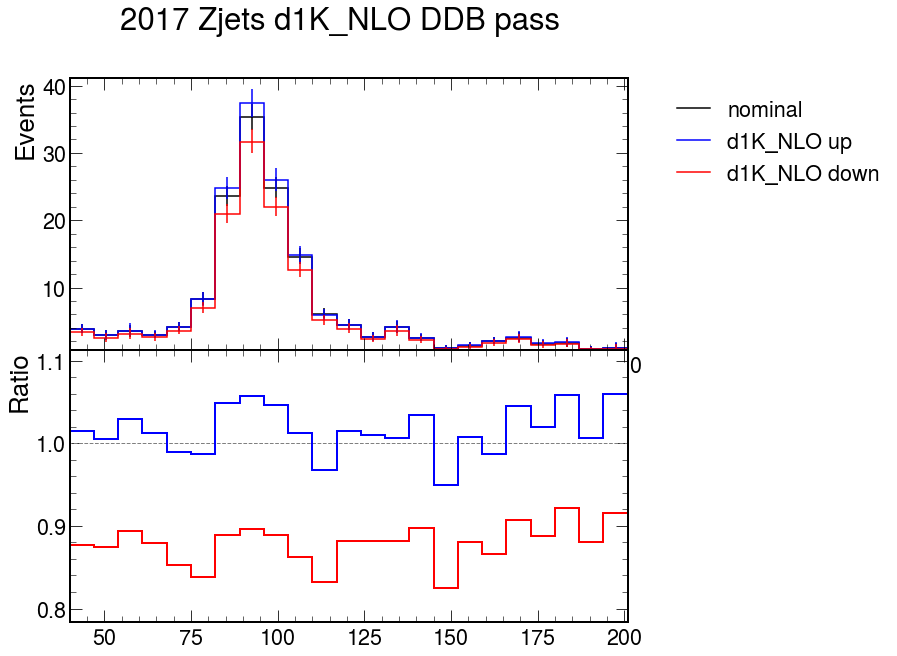

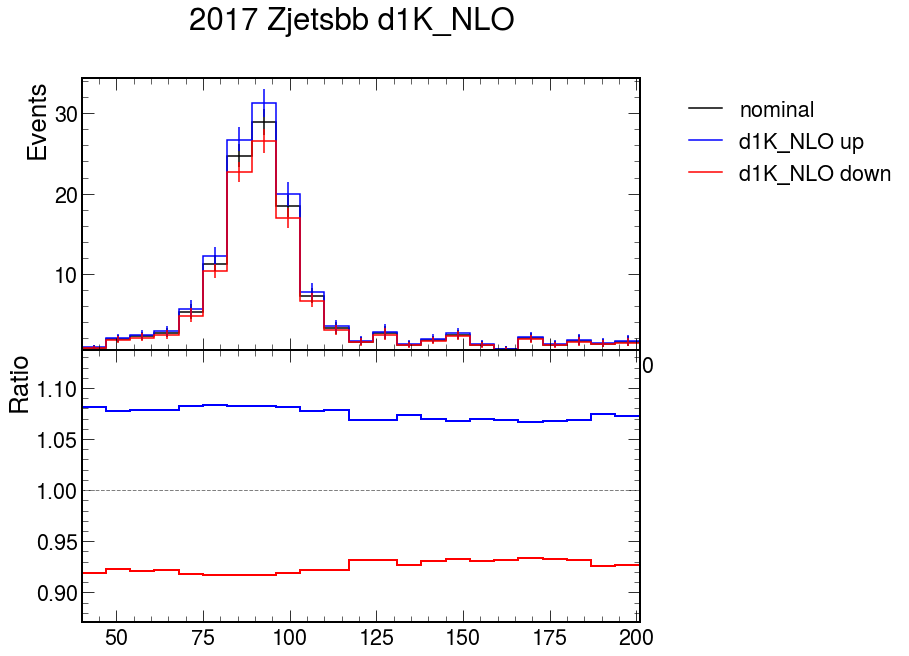

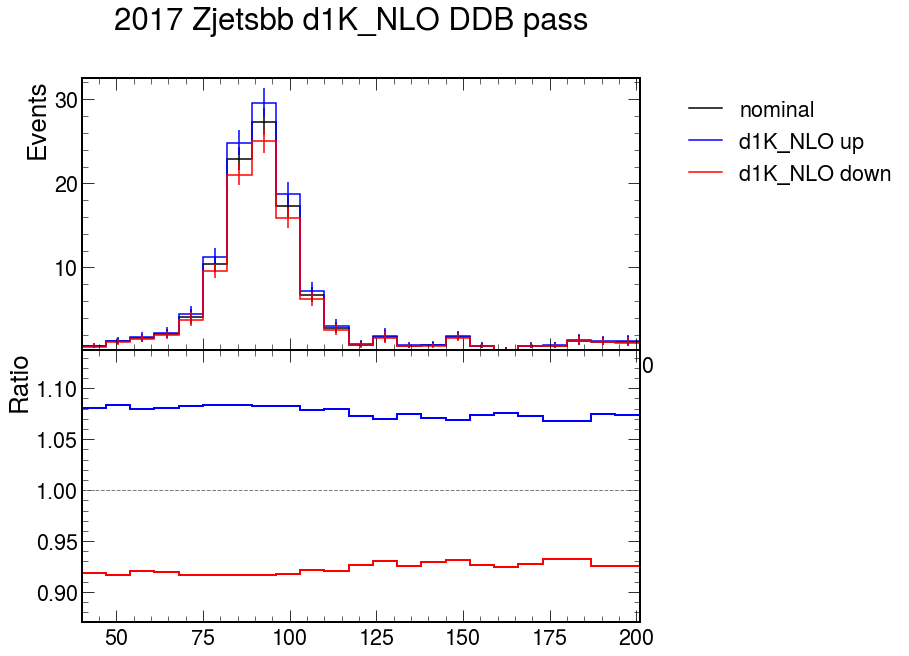

In [17]:
s = 'd1K_NLO'

plot_syst(h.integrate('process','Wjets').sum('genflavor'),s,year +' Wjets '+s,year+'/syst_'+s+'/Wjets')
plot_syst(g.integrate('process','Wjets').sum('genflavor'),s,year + ' Wjets '+s+' DDB pass', year+'/syst_'+s+'/Wjets_pass')

plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(0,3)),s,year+' Zjets '+s,year+'/syst_'+s+'/Zjets')
plot_syst(g.integrate('process','Zjets').integrate('genflavor',int_range=slice(0,3)),s,year+' Zjets '+s+' DDB pass', year+'/syst_'+s+'/Zjets_pass')
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(3,4)),s,year+' Zjetsbb '+s,year+'/syst_'+s+'/Zjetsbb')
plot_syst(g.integrate('process','Zjets').integrate('genflavor',int_range=slice(3,4)),s,year+' Zjetsbb '+s+' DDB pass', year+'/syst_'+s+'/Zjetsbb_pass')

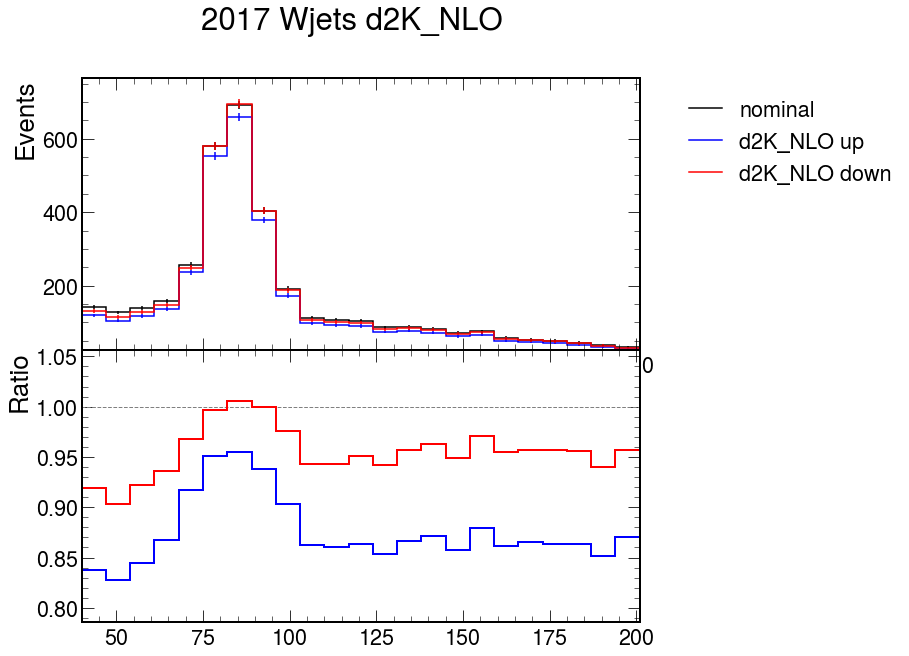

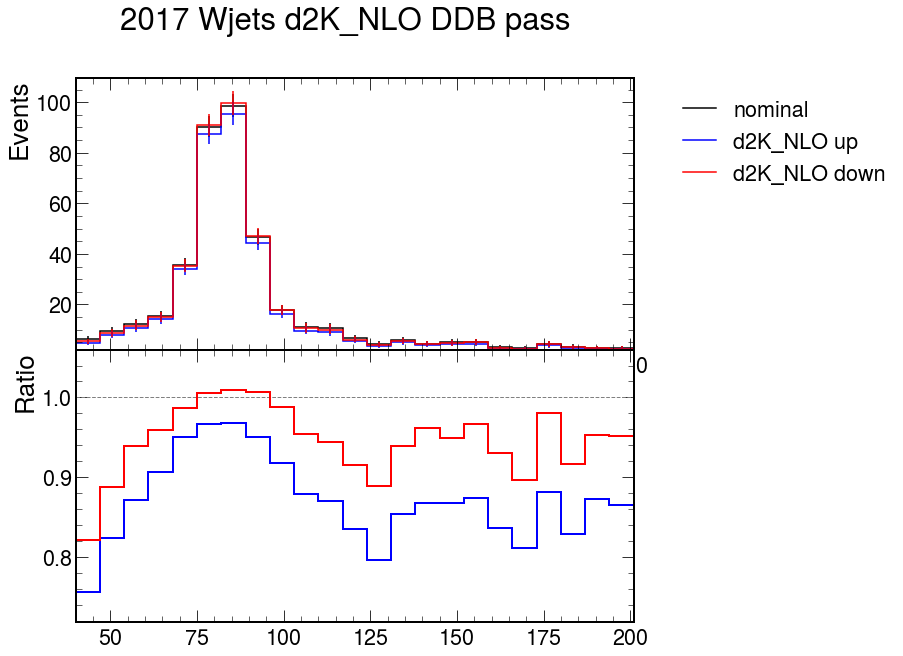

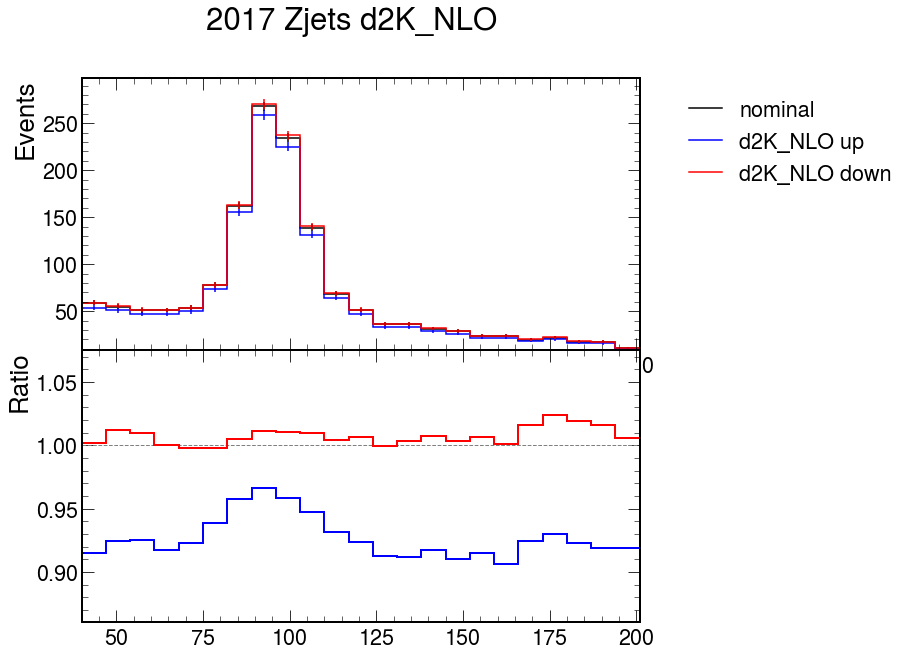

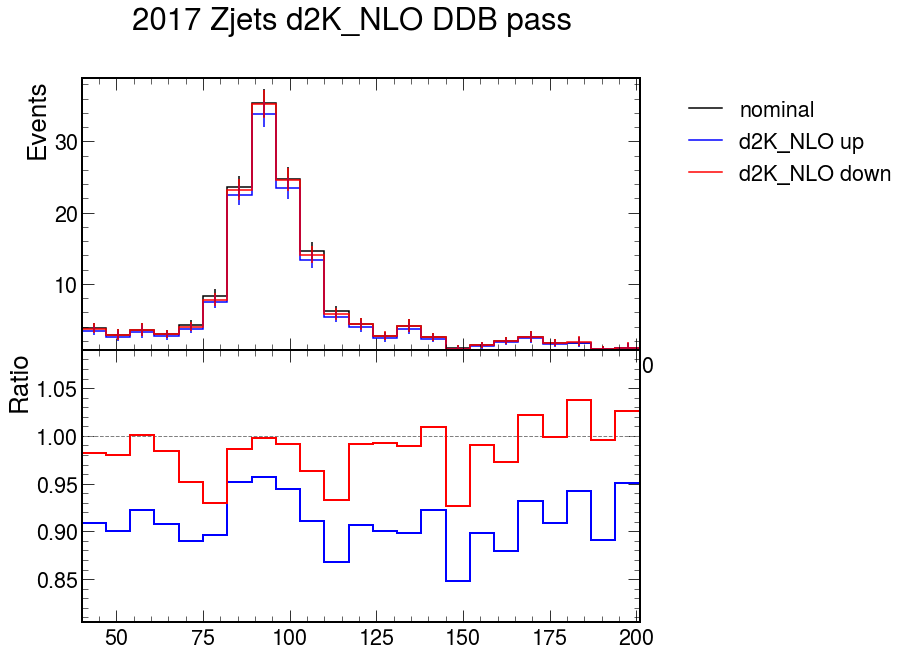

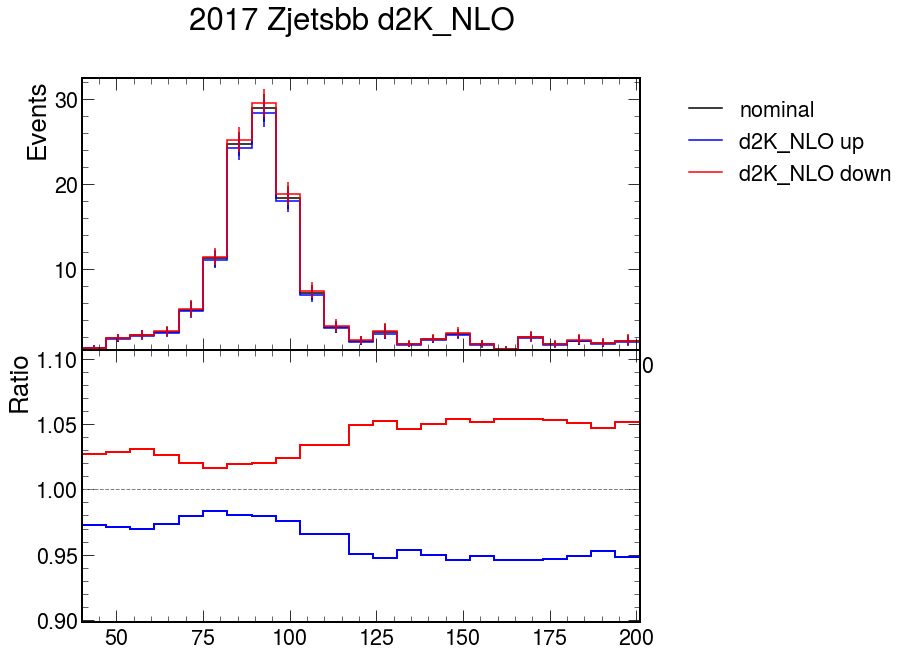

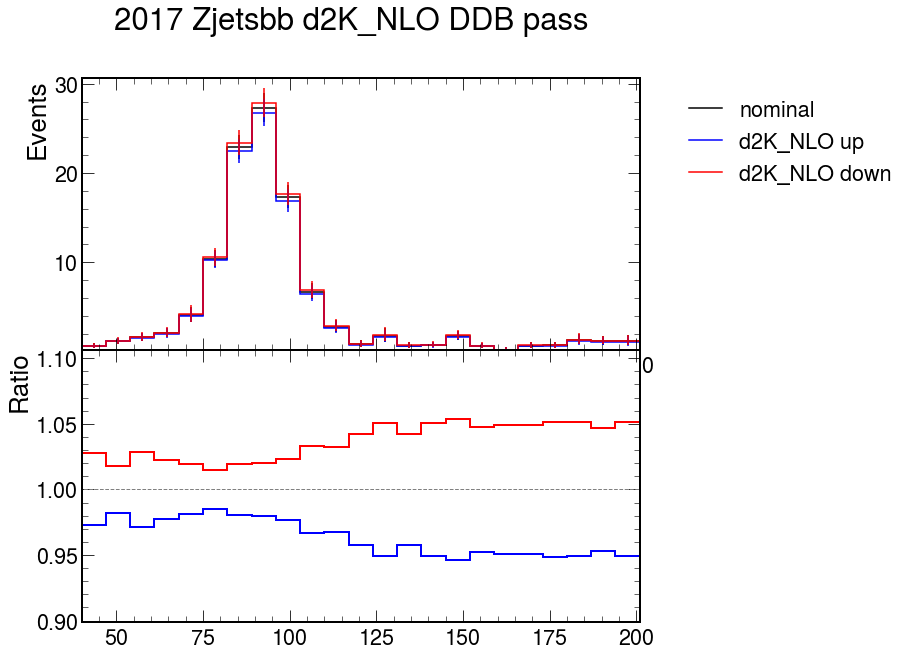

In [18]:
s = 'd2K_NLO'

plot_syst(h.integrate('process','Wjets').sum('genflavor'),s,year +' Wjets '+s,year+'/syst_'+s+'/Wjets')
plot_syst(g.integrate('process','Wjets').sum('genflavor'),s,year + ' Wjets '+s+' DDB pass', year+'/syst_'+s+'/Wjets_pass')

plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(0,3)),s,year+' Zjets '+s,year+'/syst_'+s+'/Zjets')
plot_syst(g.integrate('process','Zjets').integrate('genflavor',int_range=slice(0,3)),s,year+' Zjets '+s+' DDB pass', year+'/syst_'+s+'/Zjets_pass')
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(3,4)),s,year+' Zjetsbb '+s,year+'/syst_'+s+'/Zjetsbb')
plot_syst(g.integrate('process','Zjets').integrate('genflavor',int_range=slice(3,4)),s,year+' Zjetsbb '+s+' DDB pass', year+'/syst_'+s+'/Zjetsbb_pass')

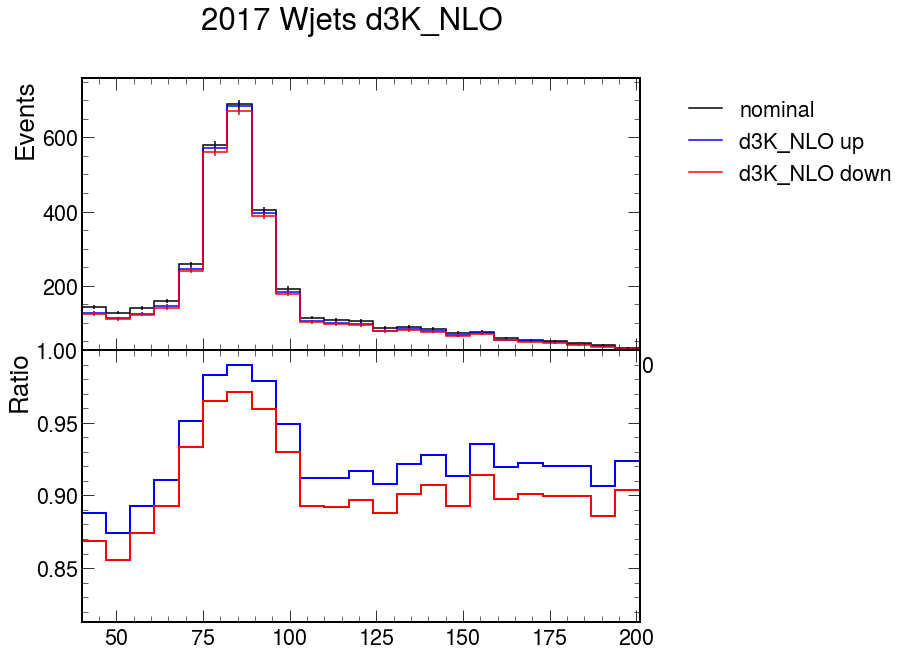

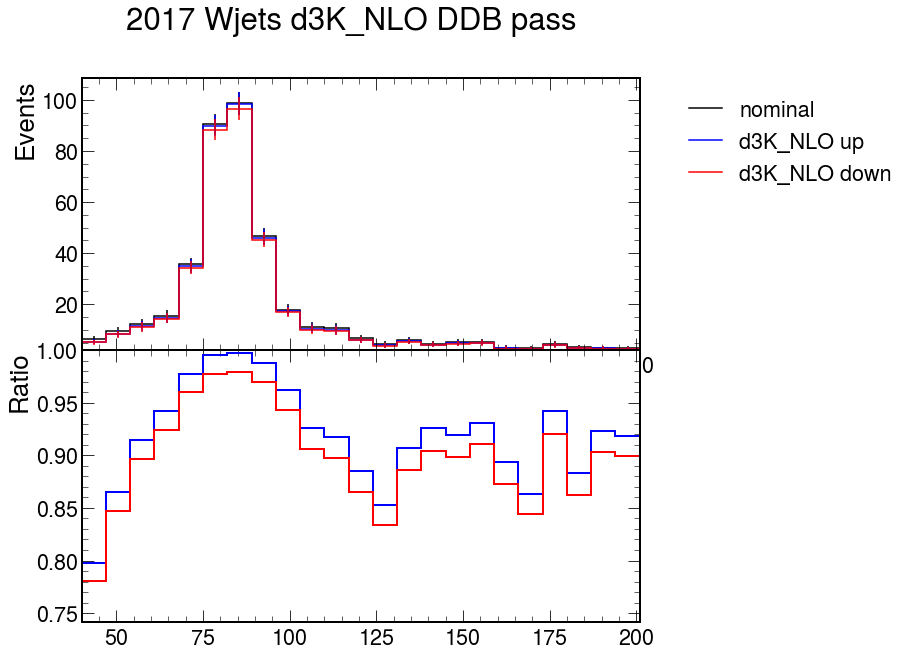

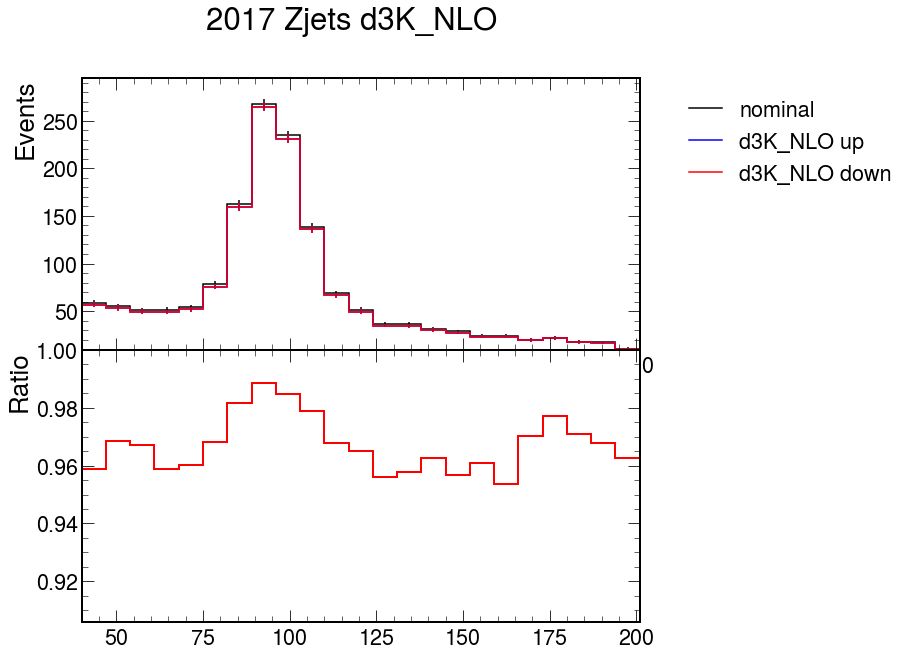

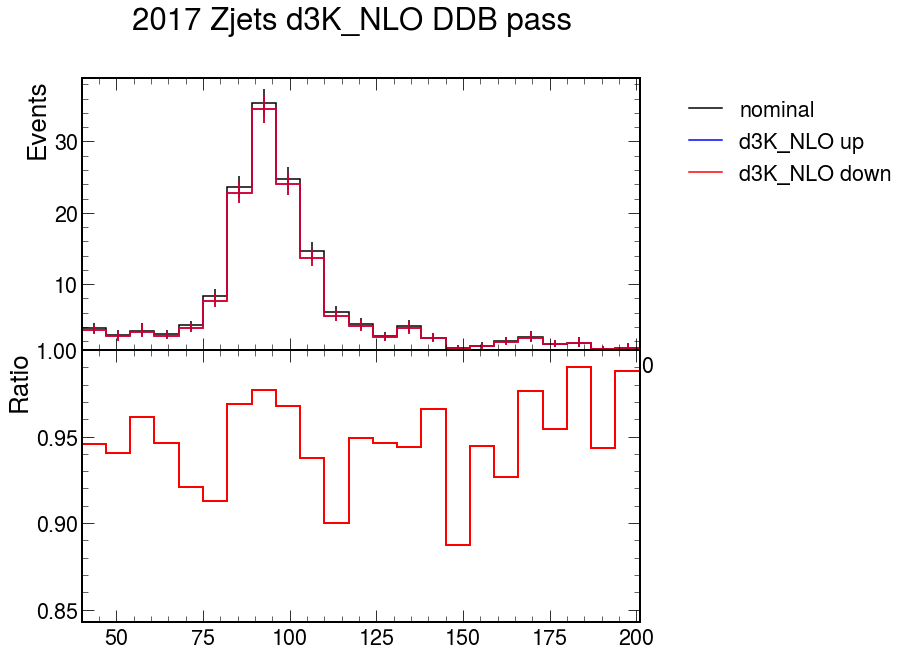

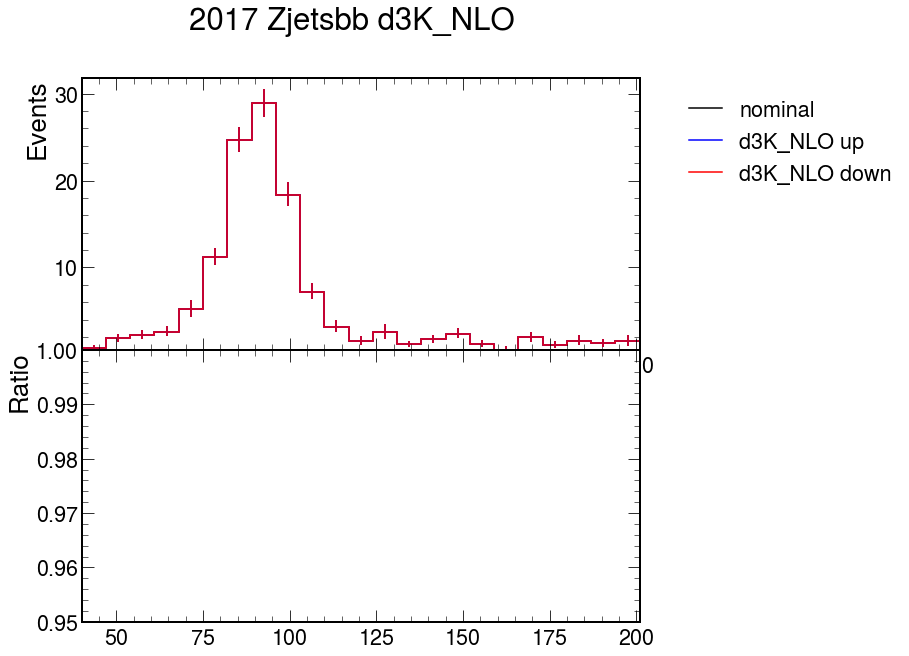

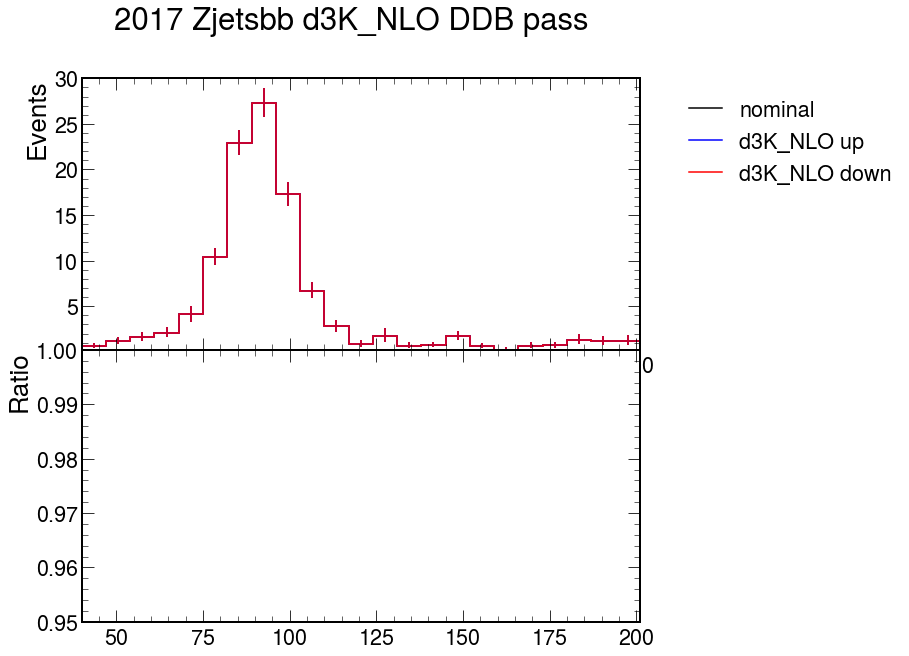

In [19]:
s = 'd3K_NLO'

plot_syst(h.integrate('process','Wjets').sum('genflavor'),s,year +' Wjets '+s,year+'/syst_'+s+'/Wjets')
plot_syst(g.integrate('process','Wjets').sum('genflavor'),s,year + ' Wjets '+s+' DDB pass', year+'/syst_'+s+'/Wjets_pass')

plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(0,3)),s,year+' Zjets '+s,year+'/syst_'+s+'/Zjets')
plot_syst(g.integrate('process','Zjets').integrate('genflavor',int_range=slice(0,3)),s,year+' Zjets '+s+' DDB pass', year+'/syst_'+s+'/Zjets_pass')
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(3,4)),s,year+' Zjetsbb '+s,year+'/syst_'+s+'/Zjetsbb')
plot_syst(g.integrate('process','Zjets').integrate('genflavor',int_range=slice(3,4)),s,year+' Zjetsbb '+s+' DDB pass', year+'/syst_'+s+'/Zjetsbb_pass')

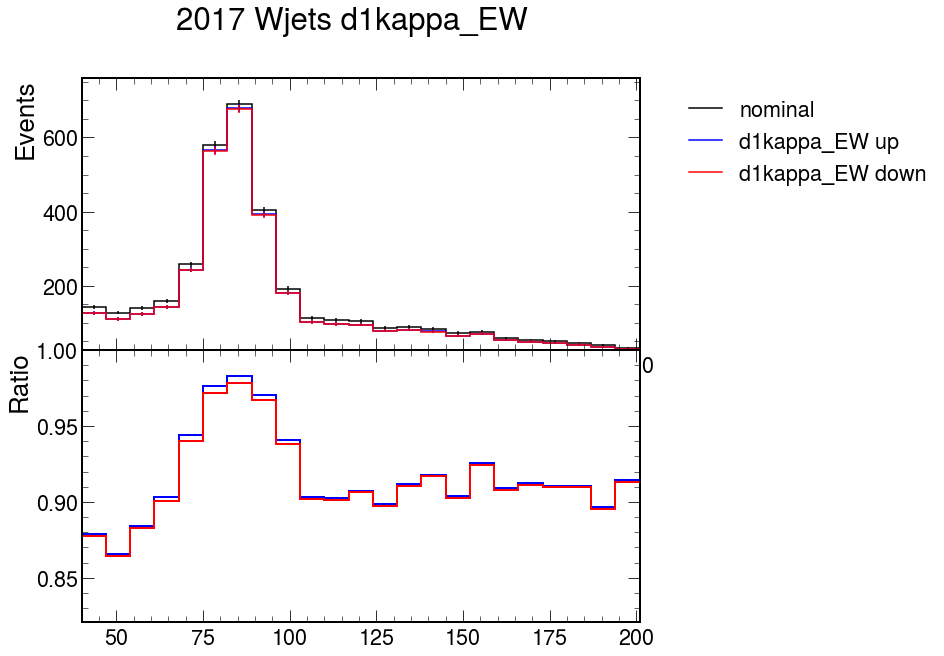

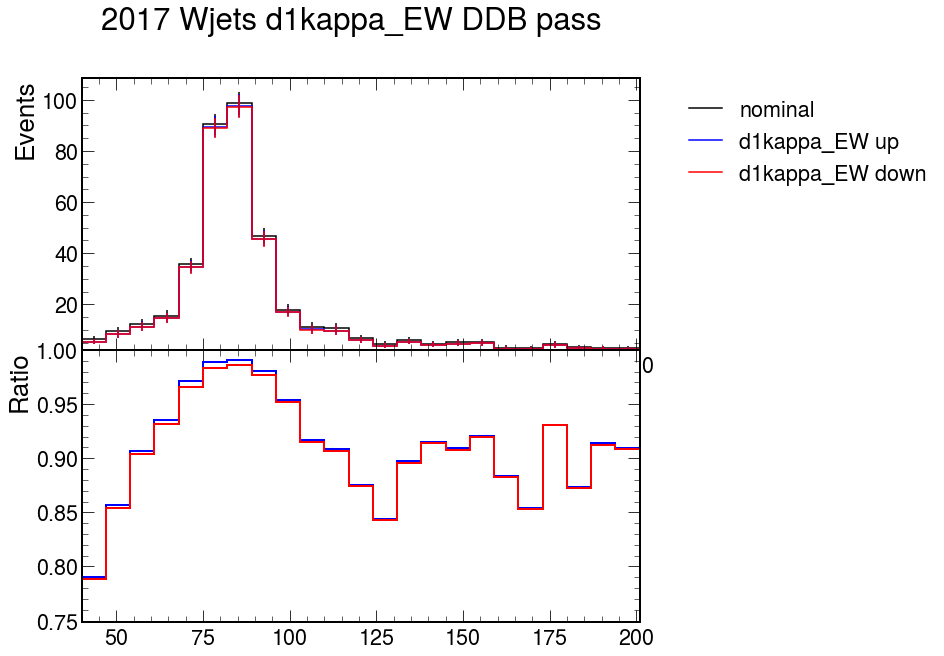

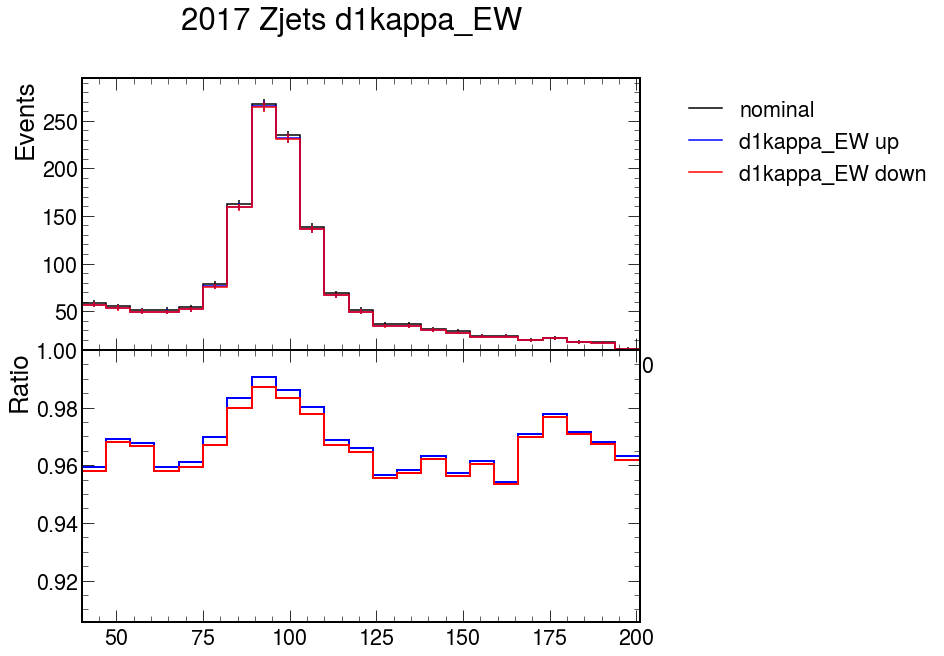

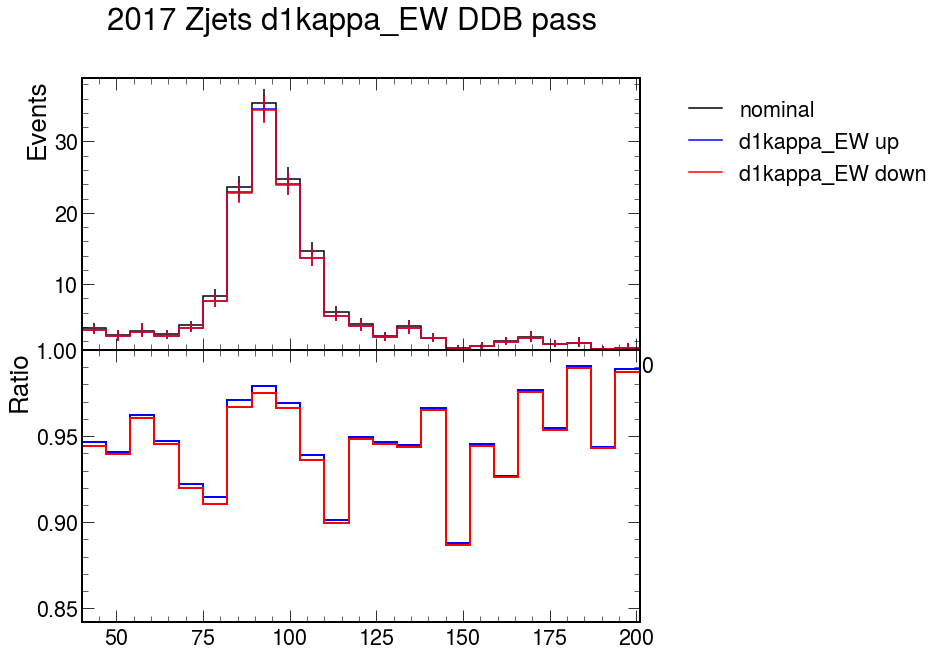

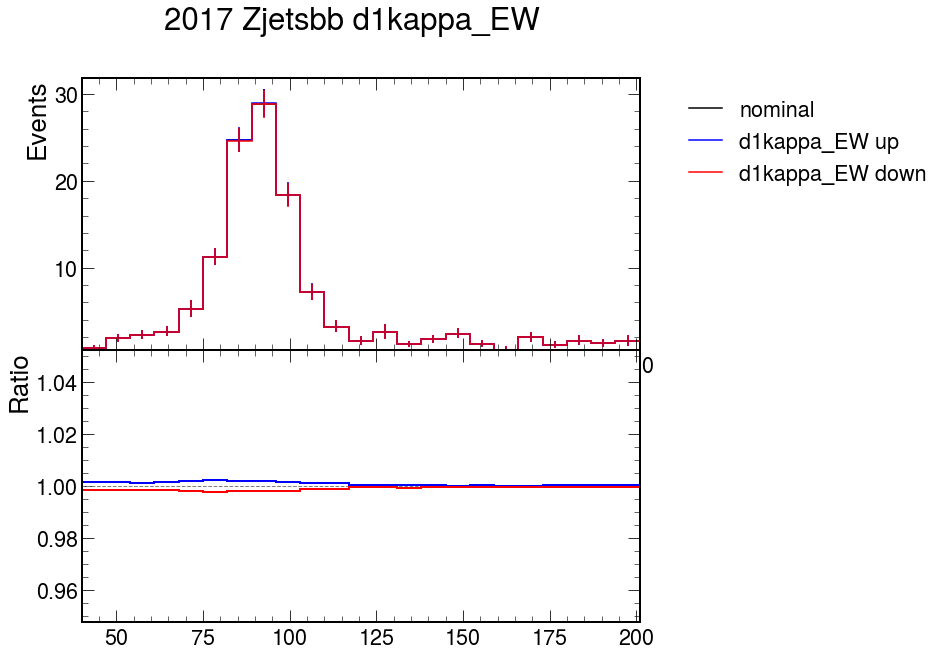

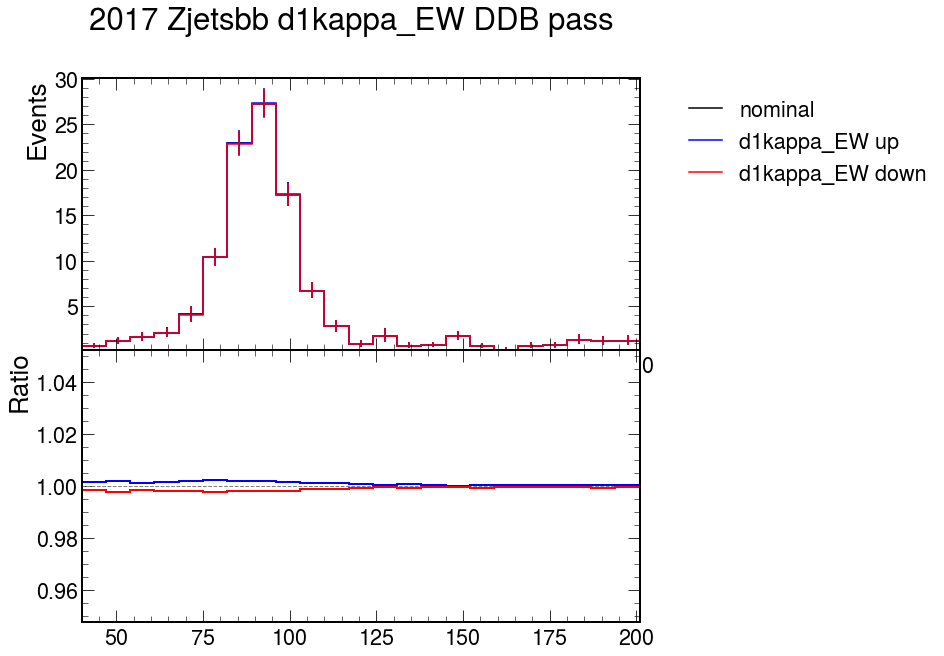

In [21]:
s = 'd1kappa_EW'

plot_syst(h.integrate('process','Wjets').sum('genflavor'),s,year +' Wjets '+s,year+'/syst_'+s+'/Wjets')
plot_syst(g.integrate('process','Wjets').sum('genflavor'),s,year + ' Wjets '+s+' DDB pass', year+'/syst_'+s+'/Wjets_pass')

plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(0,3)),s,year+' Zjets '+s,year+'/syst_'+s+'/Zjets')
plot_syst(g.integrate('process','Zjets').integrate('genflavor',int_range=slice(0,3)),s,year+' Zjets '+s+' DDB pass', year+'/syst_'+s+'/Zjets_pass')
plot_syst(h.integrate('process','Zjets').integrate('genflavor',int_range=slice(3,4)),s,year+' Zjetsbb '+s,year+'/syst_'+s+'/Zjetsbb')
plot_syst(g.integrate('process','Zjets').integrate('genflavor',int_range=slice(3,4)),s,year+' Zjetsbb '+s+' DDB pass', year+'/syst_'+s+'/Zjetsbb_pass')

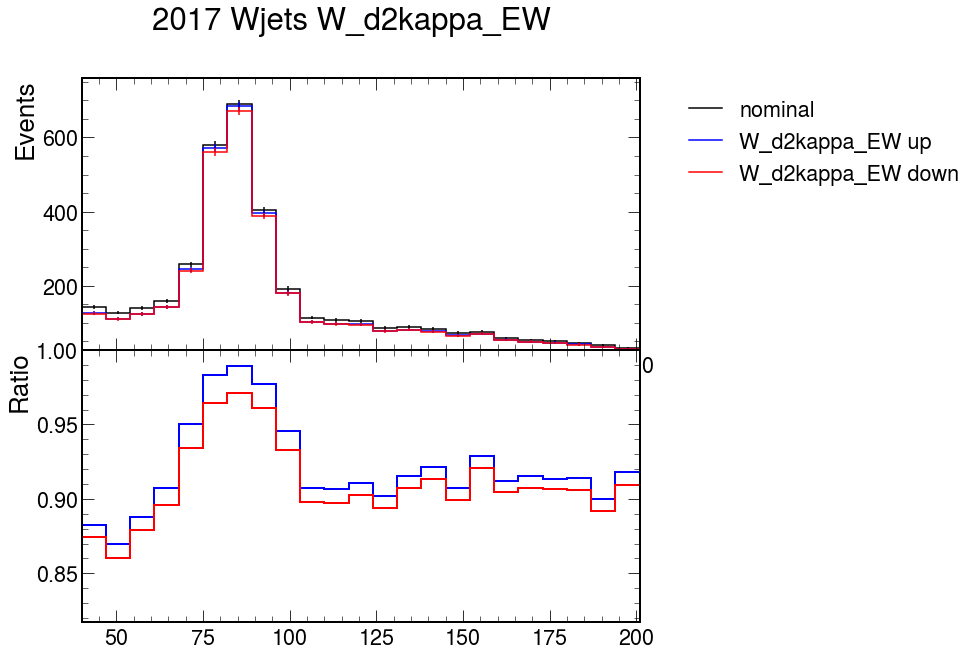

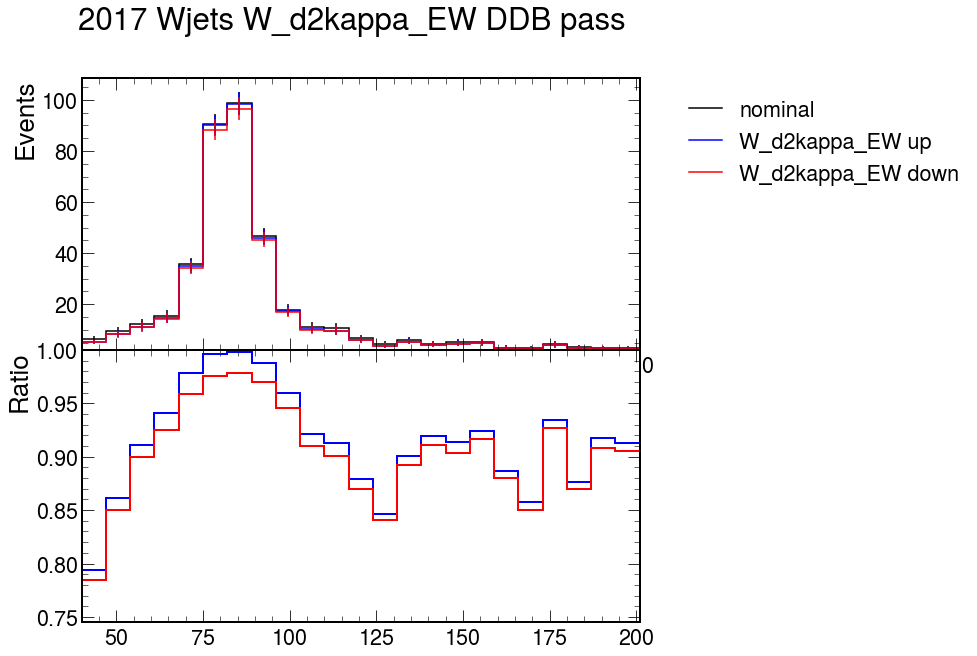

In [22]:
for p in ['Wjets']:
    plot_syst(h.integrate('process',p).sum('genflavor'),'W_d2kappa_EW',year+' '+p + ' W_d2kappa_EW',year+'/syst_W_d2kappa_EW/'+p)
    plot_syst(g.integrate('process',p).sum('genflavor'),'W_d2kappa_EW',year + ' ' + p + ' W_d2kappa_EW DDB pass', year+'/syst_W_d2kappa_EW/'+p+"_pass")

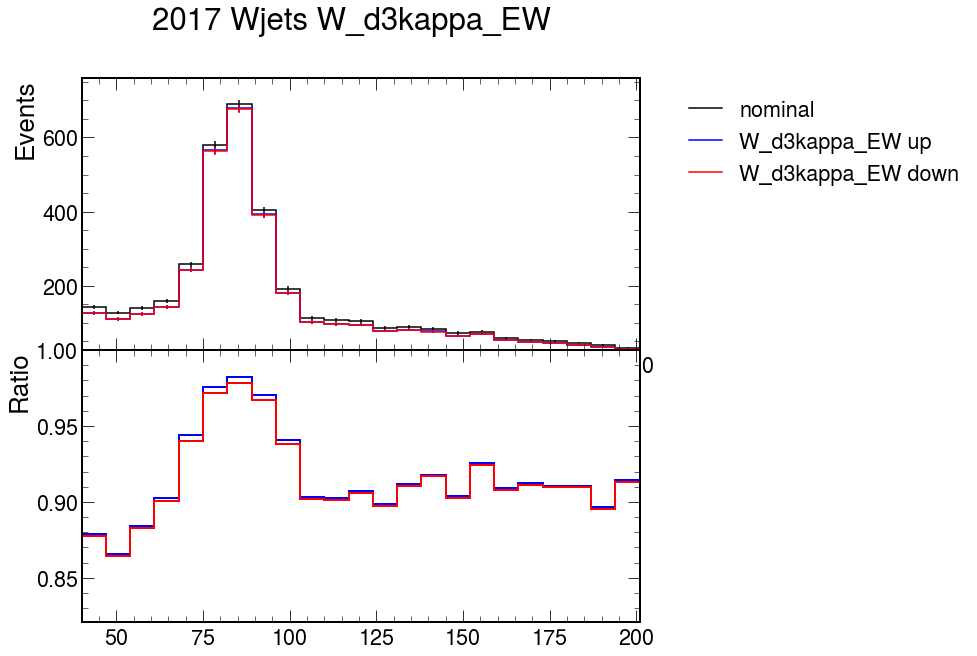

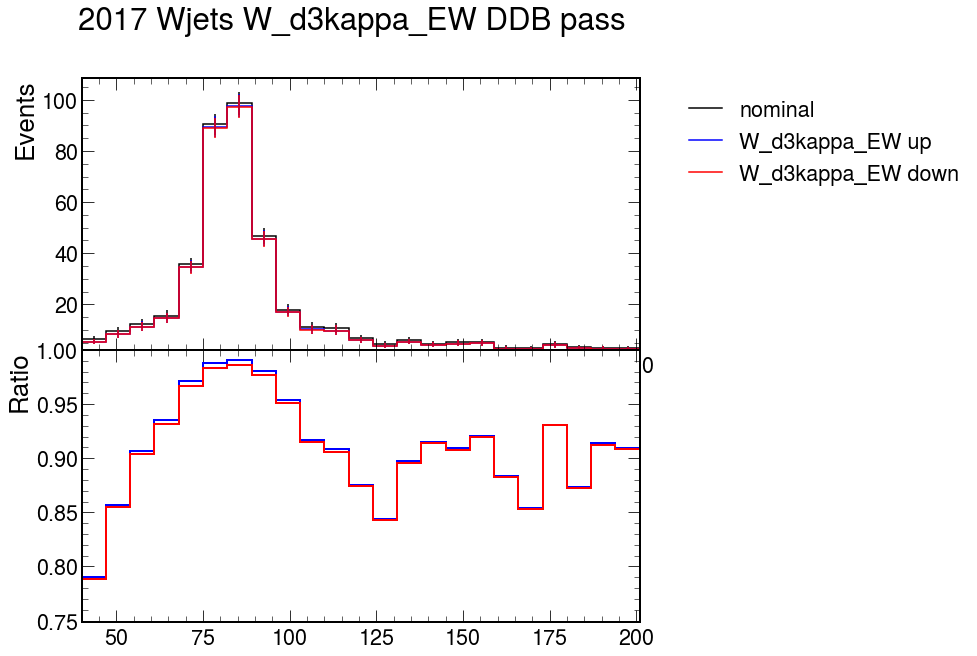

In [23]:
for p in ['Wjets']:
    plot_syst(h.integrate('process',p).sum('genflavor'),'W_d3kappa_EW',year+' '+p + ' W_d3kappa_EW',year+'/syst_W_d3kappa_EW/'+p)
    plot_syst(g.integrate('process',p).sum('genflavor'),'W_d3kappa_EW',year + ' ' + p + ' W_d3kappa_EW DDB pass', year+'/syst_W_d3kappa_EW/'+p+"_pass") 

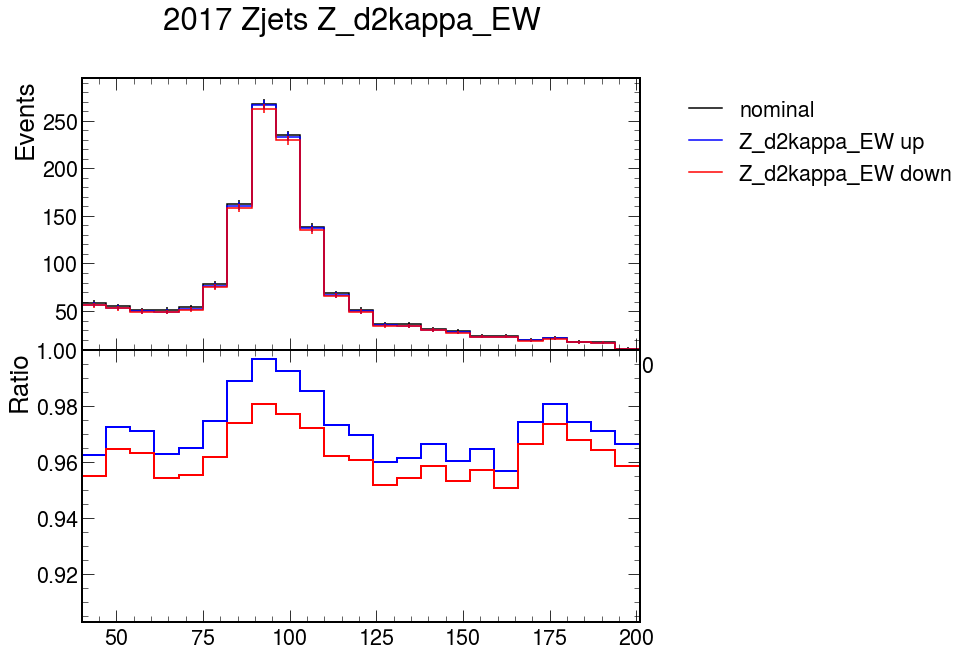

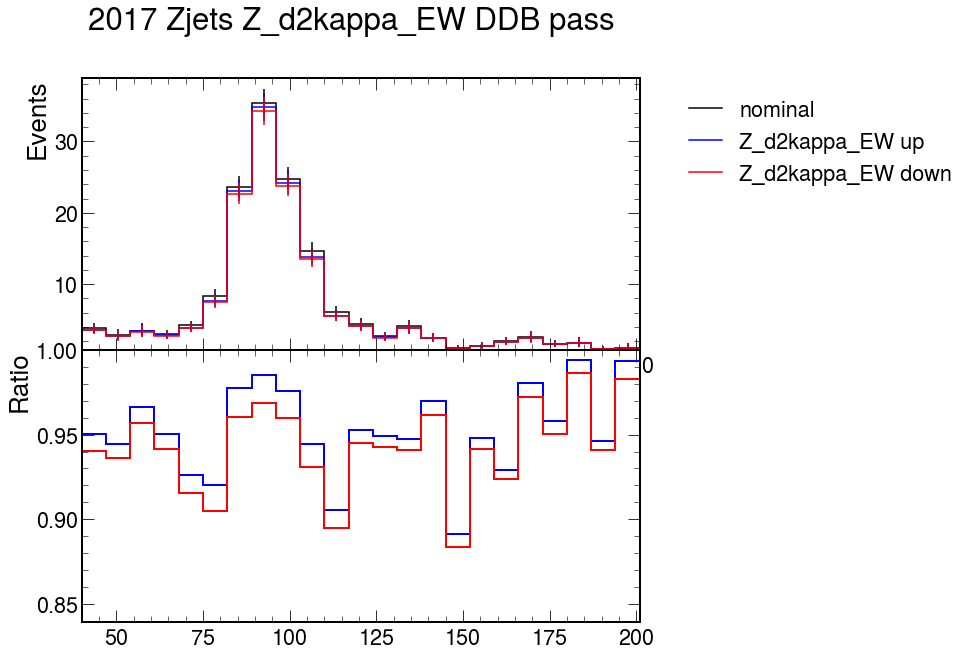

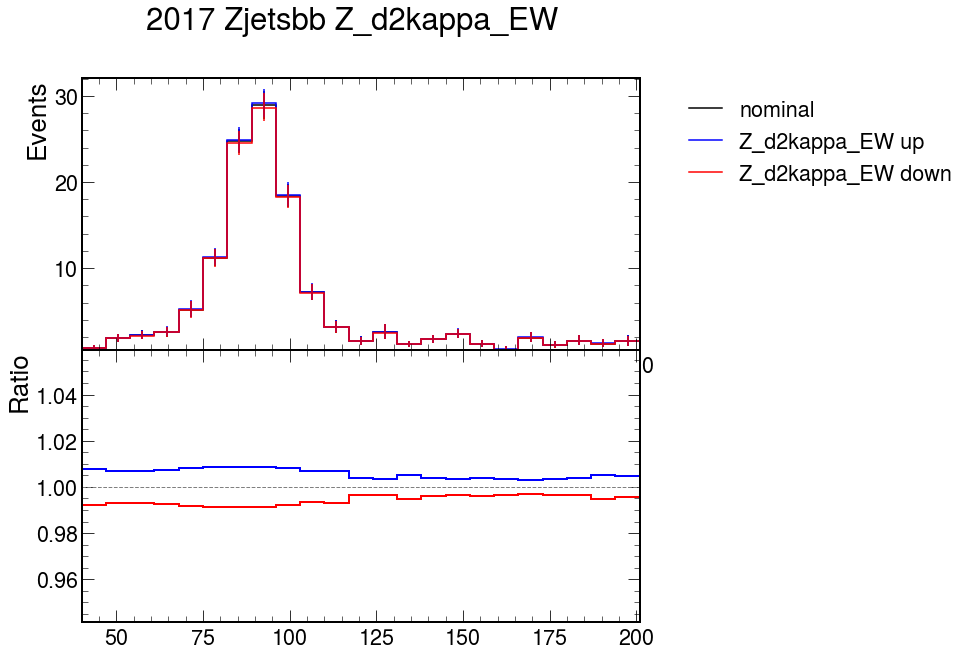

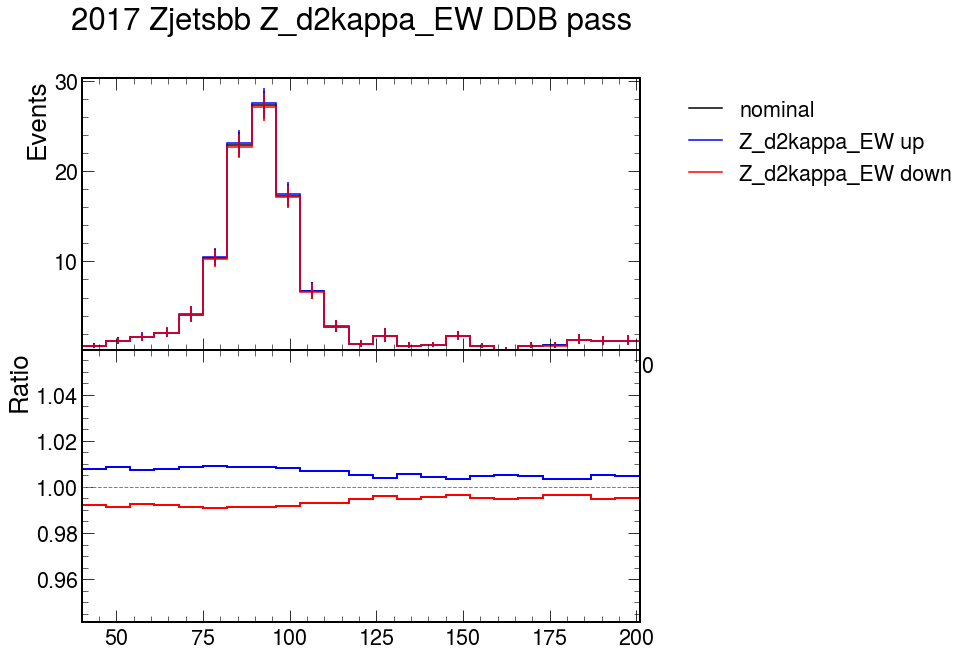

In [24]:
for p in ['Zjets']:
    plot_syst(h.integrate('process',p).integrate('genflavor',int_range=slice(0,3)),'Z_d2kappa_EW',year+' '+p+' Z_d2kappa_EW',year+'/syst_Z_d2kappa_EW/'+p)
    plot_syst(g.integrate('process',p).integrate('genflavor',int_range=slice(0,3)),'Z_d2kappa_EW',year+' '+p+' Z_d2kappa_EW DDB pass', year+'/syst_Z_d2kappa_EW/'+p+'_pass')
    
    plot_syst(h.integrate('process',p).integrate('genflavor',int_range=slice(3,4)),'Z_d2kappa_EW',year+' '+p+'bb Z_d2kappa_EW',year+'/syst_Z_d2kappa_EW/'+p+'bb')
    plot_syst(g.integrate('process',p).integrate('genflavor',int_range=slice(3,4)),'Z_d2kappa_EW',year+' '+p+'bb Z_d2kappa_EW DDB pass', year+'/syst_Z_d2kappa_EW/'+p+'bb_pass')

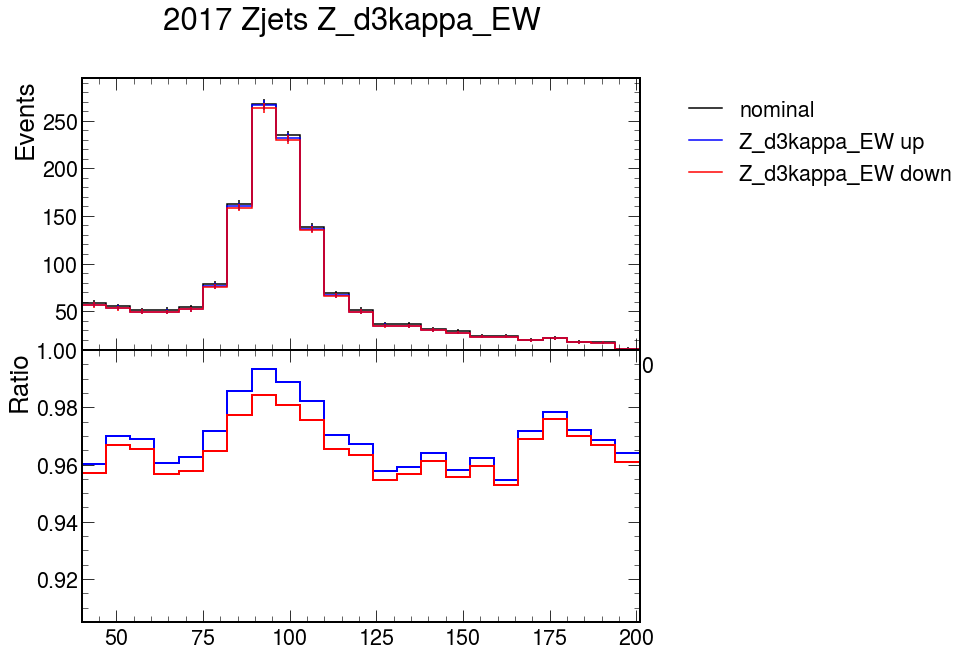

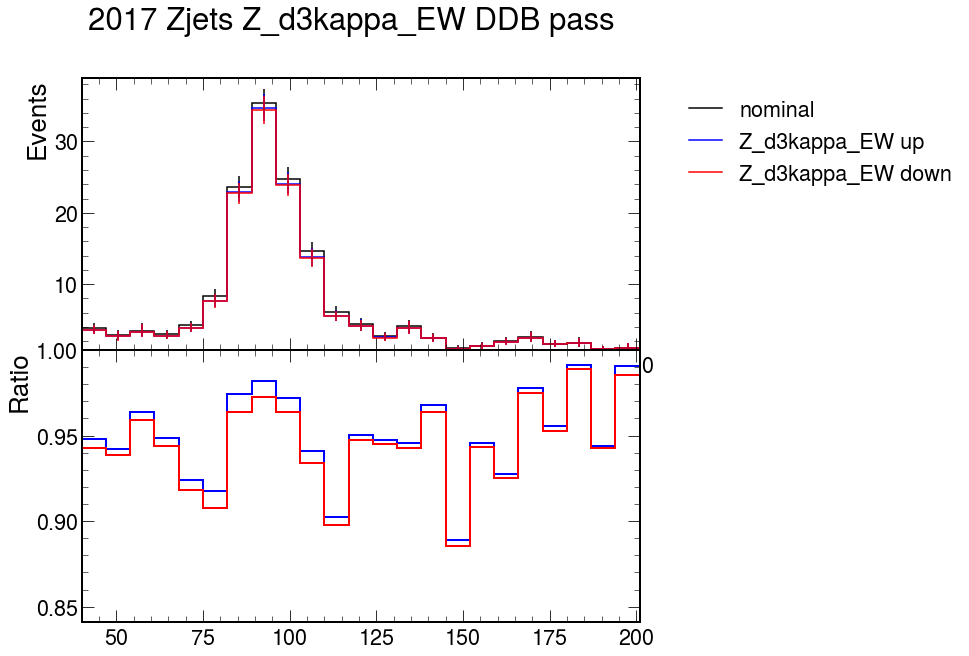

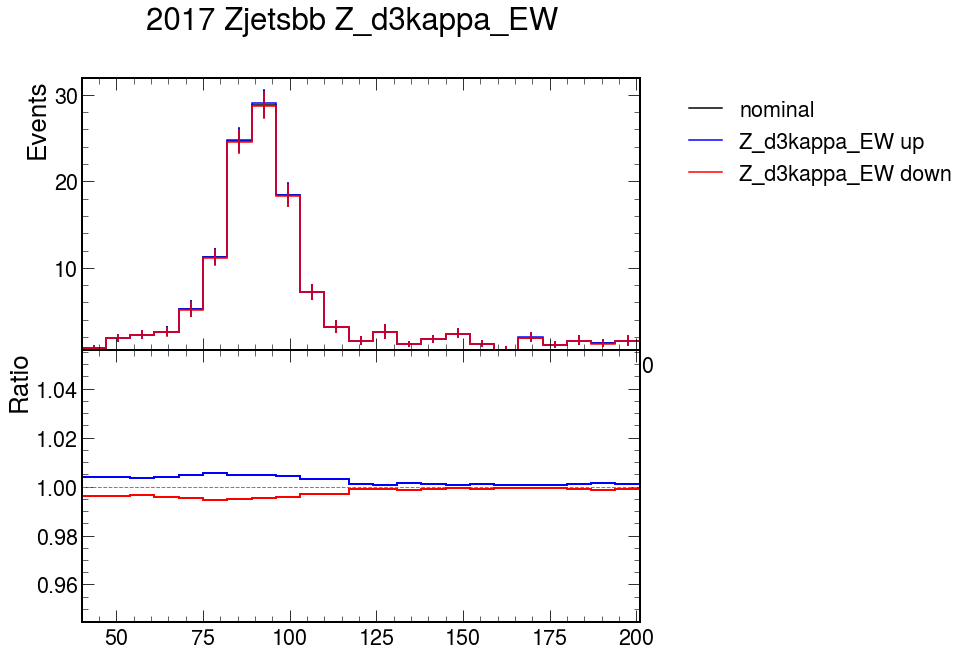

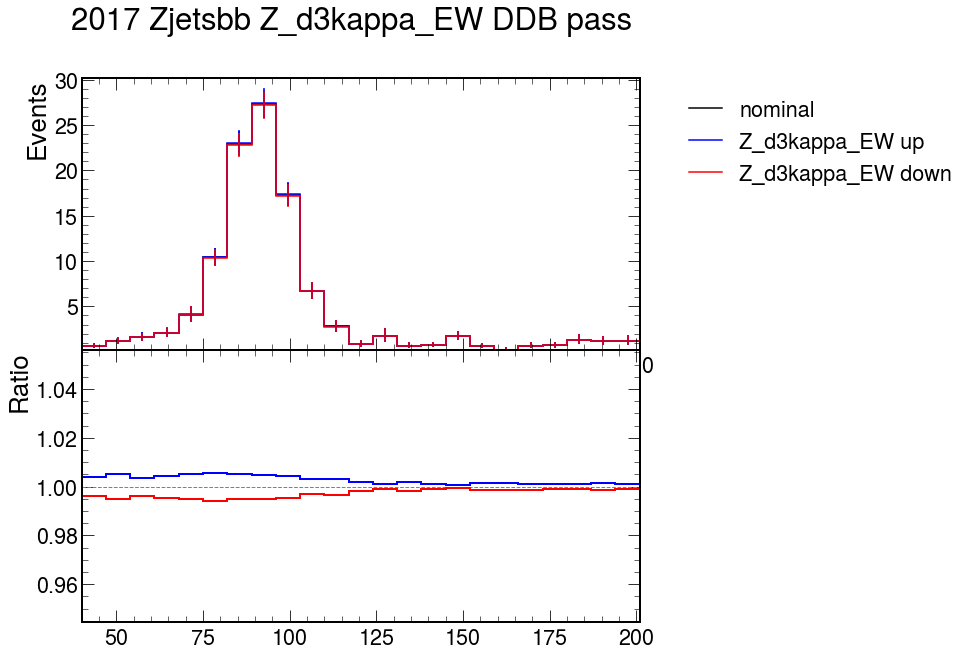

In [25]:
for p in ['Zjets']:
    plot_syst(h.integrate('process',p).integrate('genflavor',int_range=slice(0,3)),'Z_d3kappa_EW',year+' '+p+' Z_d3kappa_EW',year+'/syst_Z_d3kappa_EW/'+p)
    plot_syst(g.integrate('process',p).integrate('genflavor',int_range=slice(0,3)),'Z_d3kappa_EW',year+' '+p+' Z_d3kappa_EW DDB pass', year+'/syst_Z_d3kappa_EW/'+p+'_pass')
    
    plot_syst(h.integrate('process',p).integrate('genflavor',int_range=slice(3,4)),'Z_d3kappa_EW',year+' '+p+'bb Z_d3kappa_EW',year+'/syst_Z_d3kappa_EW/'+p+'bb')
    plot_syst(g.integrate('process',p).integrate('genflavor',int_range=slice(3,4)),'Z_d3kappa_EW',year+' '+p+'bb Z_d3kappa_EW DDB pass', year+'/syst_Z_d3kappa_EW/'+p+'bb_pass') 